In [99]:
# ============================================================
# IDENTITAS PROYEK
# ============================================================

NAMA_PROYEK = "Klasifikasi Kondisi Gelombang Laut"
NAMA_MAHASISWA = "Putri Fadhilah Zuhairah"
NIM = "ISI_NIM"
EMAIL = "ISI_EMAIL"

print("Nama proyek:", NAMA_PROYEK)
print("Nama mahasiswa:", NAMA_MAHASISWA)
print("NIM:", NIM)
print("Email:", EMAIL)

Nama proyek: Klasifikasi Kondisi Gelombang Laut
Nama mahasiswa: Putri Fadhilah Zuhairah
NIM: ISI_NIM
Email: ISI_EMAIL


In [100]:
# ============================================================
# PERTANYAAN BISNIS
# ============================================================

business_questions = {

    "BQ1": """
    Bagaimana kondisi gelombang laut pada masing-masing wilayah
    perairan berdasarkan data cuaca dan kondisi laut?
    """,

    "BQ2": """
    Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
    dan kecepatan arus terhadap kategori kondisi gelombang laut?
    """,

    "BQ3": """
    Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
    wilayah perairan dan waktu pengamatan?
    """,

    "BQ4": """
    Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
    Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
    waktu, dan aktivitas gempa?
    """
}

In [101]:
%pip install pandas numpy matplotlib seaborn mysql-connector-python scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [102]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\Hype GLK\AppData\Local\Python\pythoncore-3.14-64\python.exe
3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]


In [103]:
# ============================================================
# IMPORT LIBRARY
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import mysql.connector

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [104]:
# ============================================================
# TAMPILAN AWAL
# ============================================================

print("\n" + "=" * 80)
print("PROYEK:", NAMA_PROYEK)
print("NAMA  :", NAMA_MAHASISWA)
print("NIM   :", NIM)
print("EMAIL :", EMAIL)
print("=" * 80)

print("\nPERTANYAAN BISNIS")
print("-" * 80)

for kode, pertanyaan in business_questions.items():
    print(f"\n{kode}: {pertanyaan.strip()}")




PROYEK: Klasifikasi Kondisi Gelombang Laut
NAMA  : Putri Fadhilah Zuhairah
NIM   : ISI_NIM
EMAIL : ISI_EMAIL

PERTANYAAN BISNIS
--------------------------------------------------------------------------------

BQ1: Bagaimana kondisi gelombang laut pada masing-masing wilayah
    perairan berdasarkan data cuaca dan kondisi laut?

BQ2: Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
    dan kecepatan arus terhadap kategori kondisi gelombang laut?

BQ3: Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
    wilayah perairan dan waktu pengamatan?

BQ4: Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
    Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
    waktu, dan aktivitas gempa?


In [ ]:
# ============================================================
# 1. GATHERING DATA DARI DATABASE MYSQL
# ============================================================

print("\n" + "=" * 80)
print("1. GATHERING DATA DARI DATABASE MYSQL")
print("=" * 80)

conn = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="root",
    database="airflow_db"
)

# ------------------------------------------------------------
# 1.1 DATA CUACA
# ------------------------------------------------------------

query_cuaca = """
SELECT *
FROM marine_data_cuaca
"""

df_cuaca = pd.read_sql(query_cuaca, conn)

print("\n[1] DATA CUACA")
print("Jumlah baris :", len(df_cuaca))
print("Jumlah kolom :", len(df_cuaca.columns))

print("\nKolom:")
print(df_cuaca.columns.tolist())

print("\nContoh data:")
print(df_cuaca.head())

# ------------------------------------------------------------
# 1.2 DATA KONDISI LAUT
# ------------------------------------------------------------

query_utama = """
SELECT *
FROM marine_data_utama
"""

df_utama = pd.read_sql(query_utama, conn)

print("\n[2] DATA KONDISI LAUT")
print("Jumlah baris :", len(df_utama))
print("Jumlah kolom :", len(df_utama.columns))

print("\nKolom:")
print(df_utama.columns.tolist())

print("\nContoh data:")
print(df_utama.head())

# ------------------------------------------------------------
# 1.3 DATA GEMPA
# ------------------------------------------------------------

query_gempa = """
SELECT *
FROM marine_data_gempa
"""

df_gempa = pd.read_sql(query_gempa, conn)

print("\n[3] DATA GEMPA")
print("Jumlah baris :", len(df_gempa))
print("Jumlah kolom :", len(df_gempa.columns))

print("\nKolom:")
print(df_gempa.columns.tolist())

print("\nContoh data:")
print(df_gempa.head())


conn.close()

print("\n--- INSIGHT GATHERING DATA ---")
print("""
Data berhasil dikumpulkan dari tiga sumber, yaitu data cuaca,
data kondisi laut, dan data gempa. Ketiga sumber data ini akan
digunakan sebagai dasar untuk menganalisis kondisi gelombang laut
serta faktor-faktor yang berkaitan dengannya.
""")



1. GATHERING DATA DARI DATABASE MYSQL


In [ ]:
# ============================================================
# 2. ASSESSING DATA SEBELUM CLEANING
# ============================================================

print("\n" + "=" * 80)
print("2. ASSESSING DATA SEBELUM CLEANING")
print("=" * 80)

# ------------------------------------------------------------
# 2.1 ASSESSING DATA CUACA
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA CUACA")
print("-" * 80)

print("\n--- INFO DATA ---")
df_cuaca.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_cuaca.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_cuaca.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_cuaca.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_cuaca.head())

# ------------------------------------------------------------
# 2.2 ASSESSING DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA KONDISI LAUT")
print("-" * 80)

print("\n--- INFO DATA ---")
df_utama.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_utama.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_utama.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_utama.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_utama.head())

# ------------------------------------------------------------
# 2.3 ASSESSING DATA GEMPA
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA GEMPA")
print("-" * 80)

print("\n--- INFO DATA ---")
df_gempa.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_gempa.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_gempa.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_gempa.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_gempa.head())

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATA SEBELUM CLEANING")
print("=" * 80)

print("""
Hasil pemeriksaan awal menunjukkan bahwa ketiga dataset memiliki
karakteristik dan permasalahan kualitas data yang berbeda. Data
cuaca terdiri dari 641 data dan tidak memiliki duplikasi, tetapi
kolom visibility seluruhnya kosong sehingga tidak dapat digunakan
dalam analisis. Data kondisi laut terdiri dari 5.026 data dan tidak
memiliki duplikasi, tetapi terdapat 280 nilai kosong pada wind_gust.
Data gempa terdiri dari 51 data dan tidak memiliki duplikasi, dengan
33 nilai kosong pada potensi, 18 nilai kosong pada dirasakan, dan
seluruh 51 nilai pada shakemap kosong. Temuan tersebut menjadi dasar
untuk menentukan penanganan data pada tahap cleaning sebelum data
digunakan untuk analisis selanjutnya.
""")



2. ASSESSING DATA SEBELUM CLEANING

--------------------------------------------------------------------------------
ASSESSING DATA CUACA
--------------------------------------------------------------------------------

--- INFO DATA ---
<class 'pandas.DataFrame'>
RangeIndex: 641 entries, 0 to 640
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   cuaca_id       641 non-null    int64         
 1   adm4           641 non-null    str           
 2   location_name  641 non-null    str           
 3   related_area   641 non-null    str           
 4   forecast_time  641 non-null    datetime64[us]
 5   utc_datetime   641 non-null    datetime64[us]
 6   weather        641 non-null    str           
 7   temperature    641 non-null    float64       
 8   humidity       641 non-null    float64       
 9   wind_speed     641 non-null    float64       
 10  visibility     0 non-null      object        
 11 

In [ ]:
# ============================================================
# 3. CLEANING DATA SUMBER
# ============================================================

print("\n" + "=" * 80)
print("3. CLEANING DATA SUMBER")
print("=" * 80)


# ------------------------------------------------------------
# 3.1 CLEANING DATA CUACA
# ------------------------------------------------------------

print("\n[1] CLEANING DATA CUACA")

print("Data sebelum cleaning:", df_cuaca.shape)

df_cuaca = df_cuaca.drop_duplicates()

df_cuaca["forecast_time"] = pd.to_datetime(
    df_cuaca["forecast_time"],
    errors="coerce"
)

df_cuaca["utc_datetime"] = pd.to_datetime(
    df_cuaca["utc_datetime"],
    errors="coerce"
)

fitur_cuaca = [
    "temperature",
    "humidity",
    "wind_speed"
]

for kolom in fitur_cuaca:
    df_cuaca[kolom] = pd.to_numeric(
        df_cuaca[kolom],
        errors="coerce"
    )

df_cuaca = df_cuaca.dropna(
    subset=["forecast_time"]
)

print("Data setelah cleaning:", df_cuaca.shape)


# ------------------------------------------------------------
# 3.2 CLEANING DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n[2] CLEANING DATA KONDISI LAUT")

print("Data sebelum cleaning:", df_utama.shape)

df_utama = df_utama.drop_duplicates()

df_utama["forecast_time"] = pd.to_datetime(
    df_utama["forecast_time"],
    errors="coerce"
)

fitur_laut = [
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed"
]

for kolom in fitur_laut:
    df_utama[kolom] = pd.to_numeric(
        df_utama[kolom],
        errors="coerce"
    )

df_utama = df_utama.dropna(
    subset=[
        "forecast_time",
        "wave_category"
    ]
)

print("Data setelah cleaning:", df_utama.shape)


# ------------------------------------------------------------
# 3.3 CLEANING DATA GEMPA
# ------------------------------------------------------------

print("\n[3] CLEANING DATA GEMPA")

print("Data sebelum cleaning:", df_gempa.shape)

df_gempa = df_gempa.drop_duplicates()

df_gempa["datetime_gempa"] = pd.to_datetime(
    df_gempa["datetime_gempa"],
    errors="coerce"
)

fitur_gempa = [
    "magnitude",
    "kedalaman_km",
    "latitude",
    "longitude"
]

for kolom in fitur_gempa:
    df_gempa[kolom] = pd.to_numeric(
        df_gempa[kolom],
        errors="coerce"
    )

df_gempa = df_gempa.dropna(
    subset=["datetime_gempa"]
)

print("Data setelah cleaning:", df_gempa.shape)

print("\n" + "=" * 80)
print("INSIGHT CLEANING DATA SUMBER")
print("=" * 80)

print("""
Hasil proses cleaning menunjukkan bahwa jumlah data pada ketiga
dataset tetap sama, yaitu 641 data cuaca, 5.026 data kondisi laut,
dan 51 data gempa. Proses cleaning dilakukan untuk menangani
permasalahan kualitas data yang ditemukan pada tahap assessment,
sehingga data yang digunakan pada tahap selanjutnya lebih siap
untuk dianalisis dan digabungkan.
""")



3. CLEANING DATA SUMBER

[1] CLEANING DATA CUACA


Data sebelum cleaning: (641, 12)
Data setelah cleaning: (641, 12)

[2] CLEANING DATA KONDISI LAUT
Data sebelum cleaning: (5026, 18)
Data setelah cleaning: (5026, 18)

[3] CLEANING DATA GEMPA
Data sebelum cleaning: (51, 14)
Data setelah cleaning: (51, 14)

INSIGHT CLEANING DATA SUMBER

Hasil proses cleaning menunjukkan bahwa jumlah data pada ketiga
dataset tetap sama, yaitu 641 data cuaca, 5.026 data kondisi laut,
dan 51 data gempa. Proses cleaning dilakukan untuk menangani
permasalahan kualitas data yang ditemukan pada tahap assessment,
sehingga data yang digunakan pada tahap selanjutnya lebih siap
untuk dianalisis dan digabungkan.



In [ ]:
# ============================================================
# 4. ASSESSING SETELAH CLEANING
# ============================================================

print("\n" + "=" * 80)
print("4. ASSESSING DATA SETELAH CLEANING")
print("=" * 80)


# ------------------------------------------------------------
# 4.1 DATA CUACA
# ------------------------------------------------------------

print("\n--- DATA CUACA SETELAH CLEANING ---")

print("\nMissing values:")
print(df_cuaca.isnull().sum())

print("\nDuplikat:")
print(df_cuaca.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_cuaca.describe(include="all"))


# ------------------------------------------------------------
# 4.2 DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n--- DATA KONDISI LAUT SETELAH CLEANING ---")

print("\nMissing values:")
print(df_utama.isnull().sum())

print("\nDuplikat:")
print(df_utama.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_utama.describe(include="all"))


# ------------------------------------------------------------
# 4.3 DATA GEMPA
# ------------------------------------------------------------

print("\n--- DATA GEMPA SETELAH CLEANING ---")

print("\nMissing values:")
print(df_gempa.isnull().sum())

print("\nDuplikat:")
print(df_gempa.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_gempa.describe(include="all"))

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATA SETELAH CLEANING")
print("=" * 80)

print("""
Hasil pemeriksaan setelah cleaning menunjukkan bahwa tidak terdapat
data duplikat pada ketiga dataset dan jumlah observasi tetap
dipertahankan. Namun, beberapa nilai kosong masih terdapat pada
kolom tertentu. Pada data cuaca, kolom visibility masih memiliki
641 nilai kosong, sedangkan pada data kondisi laut terdapat 280
nilai kosong pada wind_gust. Pada data gempa, terdapat nilai kosong
pada kolom potensi, dirasakan, dan shakemap. Kolom-kolom tersebut
selanjutnya tidak digunakan apabila tidak diperlukan dalam analisis,
sedangkan variabel yang digunakan untuk penggabungan dan analisis
utama tetap memiliki data yang diperlukan.
""")



4. ASSESSING DATA SETELAH CLEANING

--- DATA CUACA SETELAH CLEANING ---

Missing values:
cuaca_id           0
adm4               0
location_name      0
related_area       0
forecast_time      0
utc_datetime       0
weather            0
temperature        0
humidity           0
wind_speed         0
visibility       641
created_at         0
dtype: int64

Duplikat:
0

Statistik deskriptif:
           cuaca_id           adm4 location_name      related_area  \
count    641.000000            641           641               641   
unique          NaN              5             5                 5   
top             NaN  74.10.01.2001       Langara  Konawe Kepulauan   
freq            NaN            133           133               133   
mean     819.285491            NaN           NaN               NaN   
min        1.000000            NaN           NaN               NaN   
25%      262.000000            NaN           NaN               NaN   
50%     1026.000000            NaN           NaN 

        forecast_id  area_id      area_name               forecast_time  \
count   5026.000000     5026           5026                        5026   
unique          NaN        7              7                         NaN   
top             NaN  P.AF.02  Laut Labengki                         NaN   
freq            NaN      738            738                         NaN   
mean       8.222841      NaN            NaN  2026-10-01 19:47:26.478312   
min        0.000000      NaN            NaN         2026-09-29 00:00:00   
25%        0.000000      NaN            NaN         2026-09-29 19:00:00   
50%        0.000000      NaN            NaN         2026-09-30 21:00:00   
75%        0.000000      NaN            NaN         2026-10-04 06:00:00   
max      287.000000      NaN            NaN         2026-10-09 00:00:00   
std       38.842369      NaN            NaN                         NaN   

              weather  temperature     humidity wind_direction   wind_speed  \
count            502

In [ ]:
# ============================================================
# 5. MENGAMBIL DATASET GABUNGAN YANG SUDAH ADA
# ============================================================

print("\n" + "=" * 80)
print("5. DATASET GABUNGAN HASIL DATA WRANGLING")
print("=" * 80)

conn = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="root",
    database="airflow_db"
)

query_gabungan = """
SELECT
    forecast_id,
    area_id,
    area_name,
    forecast_time,
    latitude,
    longitude,
    temperature,
    humidity,
    wind_speed,
    wind_gust,
    wave_height,
    current_speed,
    wave_category,
    jumlah_gempa_24jam,
    magnitude_maks_24jam,
    jarak_gempa_terdekat_km
FROM dataset_gabungan_gempa
ORDER BY forecast_time
"""

df = pd.read_sql(
    query_gabungan,
    conn
)

conn.close()

print("\nUkuran dataset gabungan:", df.shape)

print("\nKolom dataset gabungan:")
print(df.columns.tolist())

print("\n5 data pertama:")
print(df.head().to_string(index=False))

# ============================================================
# INSIGHT DATASET GABUNGAN HASIL DATA WRANGLING
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT DATASET GABUNGAN HASIL DATA WRANGLING")
print("=" * 80)

print(f"""
Hasil data wrangling menghasilkan dataset gabungan sebanyak
{df.shape[0]} data dengan {df.shape[1]} variabel. Dataset ini
mengintegrasikan informasi cuaca, kondisi laut, lokasi, waktu,
dan aktivitas gempa. Variabel yang tersedia mencakup kondisi
cuaca dan laut seperti temperature, humidity, wind_speed,
wind_gust, wave_height, dan current_speed, serta informasi
gempa berupa jumlah gempa dalam 24 jam, magnitude maksimum,
dan jarak gempa terdekat. Dataset gabungan ini selanjutnya
digunakan sebagai dataset utama untuk menganalisis kondisi
gelombang laut berdasarkan faktor lingkungan, lokasi wilayah
perairan, waktu pengamatan, dan aktivitas gempa.
""")



5. DATASET GABUNGAN HASIL DATA WRANGLING


C:\Users\Hype GLK\AppData\Local\Temp\ipykernel_17100\818835006.py:39: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(



Ukuran dataset gabungan: (287, 16)

Kolom dataset gabungan:
['forecast_id', 'area_id', 'area_name', 'forecast_time', 'latitude', 'longitude', 'temperature', 'humidity', 'wind_speed', 'wind_gust', 'wave_height', 'current_speed', 'wave_category', 'jumlah_gempa_24jam', 'magnitude_maks_24jam', 'jarak_gempa_terdekat_km']

5 data pertama:
 forecast_id area_id              area_name forecast_time  latitude  longitude  temperature  humidity  wind_speed  wind_gust  wave_height  current_speed wave_category  jumlah_gempa_24jam  magnitude_maks_24jam  jarak_gempa_terdekat_km
         124 P.AF.01         Selat Labengki    2026-09-29     -3.40     122.45         26.0      84.0         2.0        9.0          0.4           0.67        Tenang                   3                   4.5               560.210017
         165 P.AF.02          Laut Labengki    2026-09-29     -3.25     122.60         26.0      85.0         3.0        9.0          0.5           0.79        Rendah                   3          

In [ ]:
# ============================================================
# 6. ASSESSING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("6. ASSESSING DATASET GABUNGAN")
print("=" * 80)

print("\n--- INFO ---")
df.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df.head())

# ============================================================
# INSIGHT ASSESSING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATASET GABUNGAN")
print("=" * 80)

print(f"""
Hasil assessment menunjukkan bahwa dataset gabungan memiliki
{df.shape[0]} data dengan {df.shape[1]} variabel. Seluruh variabel
yang digunakan dalam dataset memiliki data lengkap tanpa missing
values dan tidak ditemukan data duplikat. Dataset mencakup
7 wilayah perairan dengan masing-masing wilayah memiliki
41 data pengamatan. Variabel kondisi laut menunjukkan adanya
variasi pada tinggi gelombang, kecepatan angin, kecepatan angin
maksimum, dan kecepatan arus. Selain itu, dataset juga memuat
informasi aktivitas gempa dalam 24 jam sebelum waktu pengamatan,
sehingga dapat digunakan untuk melihat keterkaitan kondisi
gelombang dengan faktor cuaca, kondisi laut, lokasi, waktu,
dan aktivitas gempa.
""")


6. ASSESSING DATASET GABUNGAN

--- INFO ---


<class 'pandas.DataFrame'>
RangeIndex: 287 entries, 0 to 286
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   forecast_id              287 non-null    int64         
 1   area_id                  287 non-null    str           
 2   area_name                287 non-null    str           
 3   forecast_time            287 non-null    datetime64[us]
 4   latitude                 287 non-null    float64       
 5   longitude                287 non-null    float64       
 6   temperature              287 non-null    float64       
 7   humidity                 287 non-null    float64       
 8   wind_speed               287 non-null    float64       
 9   wind_gust                287 non-null    float64       
 10  wave_height              287 non-null    float64       
 11  current_speed            287 non-null    float64       
 12  wave_category            287 non-null    str   

In [ ]:
# ============================================================
# 7. CLEANING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("7. CLEANING DATASET GABUNGAN")
print("=" * 80)

print("Data sebelum cleaning:", df.shape)

df = df.drop_duplicates()

df["forecast_time"] = pd.to_datetime(
    df["forecast_time"],
    errors="coerce"
)

df = df.dropna(
    subset=["wave_category"]
)

# ------------------------------------------------------------
# KONVERSI DATA NUMERIK
# ------------------------------------------------------------

fitur_numerik = [
    "latitude",
    "longitude",
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed",
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]

for kolom in fitur_numerik:
    df[kolom] = pd.to_numeric(
        df[kolom],
        errors="coerce"
    )

df = df.dropna(
    subset=fitur_numerik + ["forecast_time"]
)

print("Data setelah cleaning:", df.shape)

# ============================================================
# INSIGHT CLEANING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT CLEANING DATASET GABUNGAN")
print("=" * 80)

print("""
Hasil proses cleaning menunjukkan bahwa jumlah data pada dataset
gabungan tetap sebanyak 287 data dengan 21 variabel. Tidak terdapat
pengurangan jumlah observasi setelah proses cleaning, sehingga
seluruh data tetap dipertahankan untuk tahap analisis selanjutnya.
Cleaning dilakukan untuk memastikan data yang digunakan berada
dalam format yang sesuai dan siap digunakan pada tahap EDA serta
pemodelan machine learning.
""")




7. CLEANING DATASET GABUNGAN
Data sebelum cleaning: (287, 21)
Data setelah cleaning: (287, 21)

INSIGHT CLEANING DATASET GABUNGAN

Hasil proses cleaning menunjukkan bahwa jumlah data pada dataset
gabungan tetap sebanyak 287 data dengan 21 variabel. Tidak terdapat
pengurangan jumlah observasi setelah proses cleaning, sehingga
seluruh data tetap dipertahankan untuk tahap analisis selanjutnya.
Cleaning dilakukan untuk memastikan data yang digunakan berada
dalam format yang sesuai dan siap digunakan pada tahap EDA serta
pemodelan machine learning.



In [ ]:
# ============================================================
# 8. ASSESSING AKHIR DATASET ANALISIS
# ============================================================

print("\n" + "=" * 80)
print("8. ASSESSING AKHIR DATASET ANALISIS")
print("=" * 80)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplikat:")
print(df.duplicated().sum())

print("\nStatistik numerik:")
print(df[fitur_numerik].describe())

print("\nDistribusi target:")
print(df["wave_category"].value_counts())

# ============================================================
# INSIGHT ASSESSING AKHIR DATASET ANALISIS
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT ASSESSING AKHIR DATASET ANALISIS")
print("=" * 80)

jumlah_data = len(df)
jumlah_missing = df.isnull().sum().sum()
jumlah_duplikat = df.duplicated().sum()

distribusi_target = df["wave_category"].value_counts()
kategori_dominan = distribusi_target.idxmax()
jumlah_dominan = distribusi_target.max()

print(f"""
Hasil assessing akhir menunjukkan bahwa dataset analisis memiliki
{jumlah_data} data dan tidak ditemukan missing values maupun data
duplikat. Variabel numerik yang digunakan memiliki nilai yang
bervariasi sehingga dapat digunakan untuk menggambarkan kondisi
cuaca, kondisi laut, lokasi, serta aktivitas gempa pada masing-masing
wilayah pengamatan. Distribusi target menunjukkan bahwa kategori
{kategori_dominan} merupakan kategori yang paling banyak ditemukan,
yaitu sebanyak {jumlah_dominan} data, sedangkan kategori lainnya
memiliki jumlah data yang lebih sedikit. Dengan kondisi tersebut,
dataset telah siap digunakan untuk tahap Exploratory Data Analysis
(EDA) dan pemodelan klasifikasi kondisi gelombang laut.
""")


8. ASSESSING AKHIR DATASET ANALISIS

Missing values:
forecast_id                0
area_id                    0
area_name                  0
forecast_time              0
latitude                   0
longitude                  0
temperature                0
humidity                   0
wind_speed                 0
wind_gust                  0
wave_height                0
current_speed              0
wave_category              0
jumlah_gempa_24jam         0
magnitude_maks_24jam       0
jarak_gempa_terdekat_km    0
tanggal                    0
jam                        0
hari                       0
hour                       0
day_of_week                0
dtype: int64

Duplikat:
0

Statistik numerik:
         latitude   longitude  temperature    humidity  wind_speed  \
count  287.000000  287.000000   287.000000  287.000000  287.000000   
mean    -4.114286  122.842857    26.317073   79.651568    7.379791   
std      0.795884    0.740223     0.857192    3.952142    2.999769   
min     -5.


10. EDA - BQ1

BQ1:
Bagaimana kondisi gelombang laut pada masing-masing wilayah
perairan berdasarkan data cuaca dan kondisi laut?


--- JUMLAH PENGAMATAN PER WILAYAH ---
area_name
Selat Labengki                   41
Laut Labengki                    41
Teluk Kendari - Moramo           41
Selat Wawoni                     41
Perairan Buton                   41
Teluk Bone Barat Kolaka Utara    41
Laut Banda Timur Wakatobi        41
Name: count, dtype: int64

--- DISTRIBUSI KATEGORI GELOMBANG ---
wave_category
Rendah    242
Tenang     45
Name: count, dtype: int64

Proporsi kategori (%):
wave_category
Rendah    84.32
Tenang    15.68
Name: proportion, dtype: float64

--- KATEGORI GELOMBANG PER WILAYAH ---
wave_category                  Rendah  Tenang
area_name                                    
Laut Banda Timur Wakatobi          41       0
Laut Labengki                      41       0
Perairan Buton                     41       0
Selat Labengki                     27      14
Selat Wawoni   

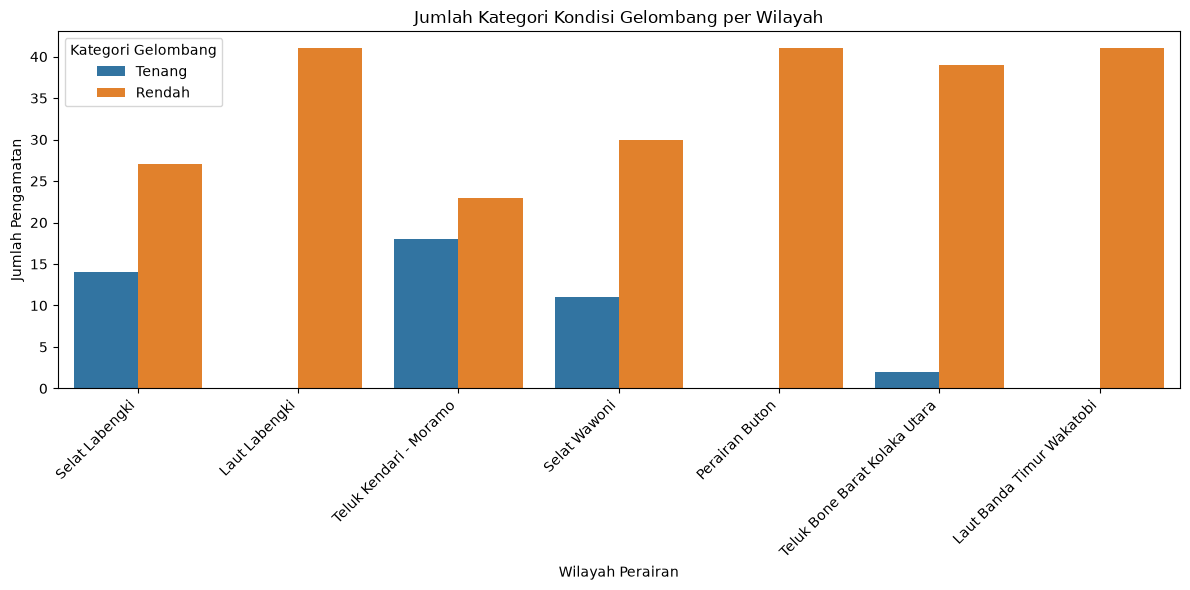

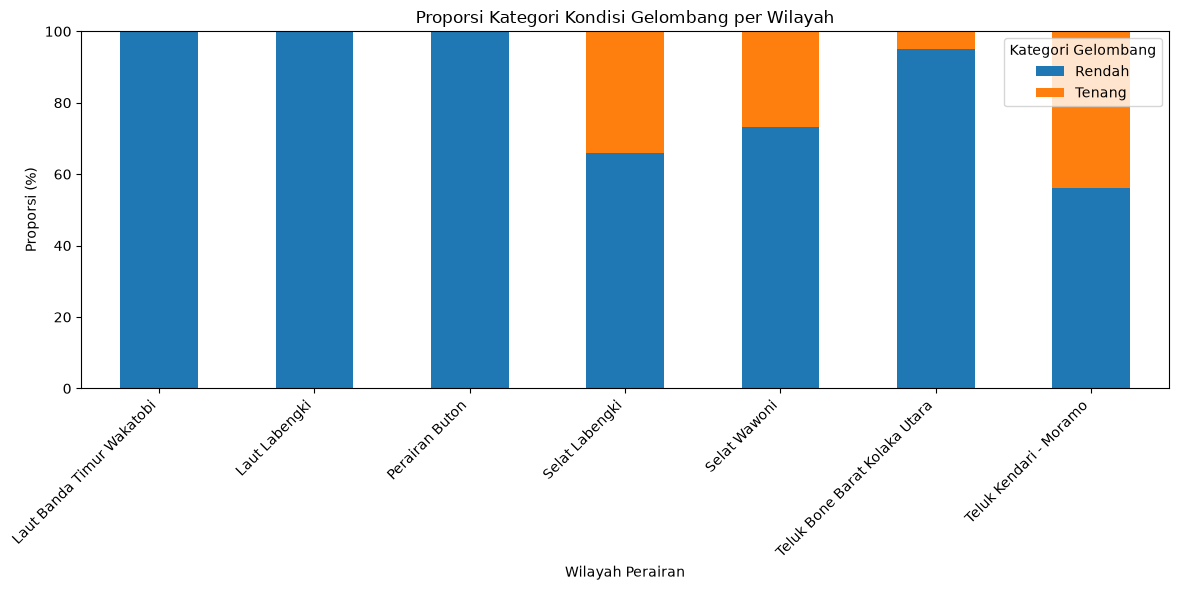

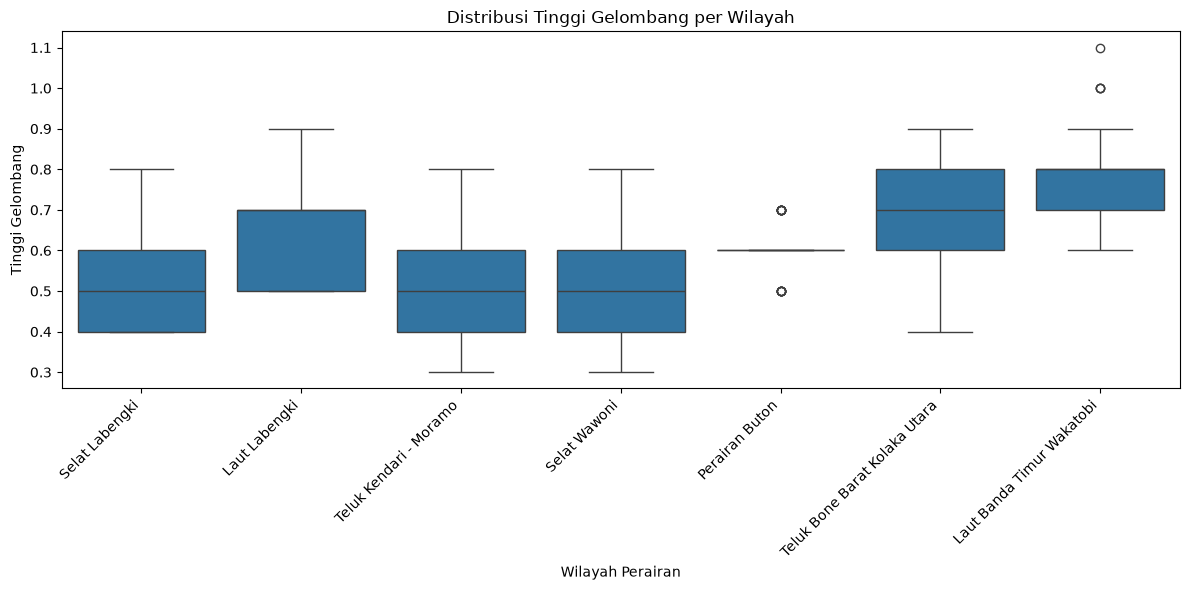

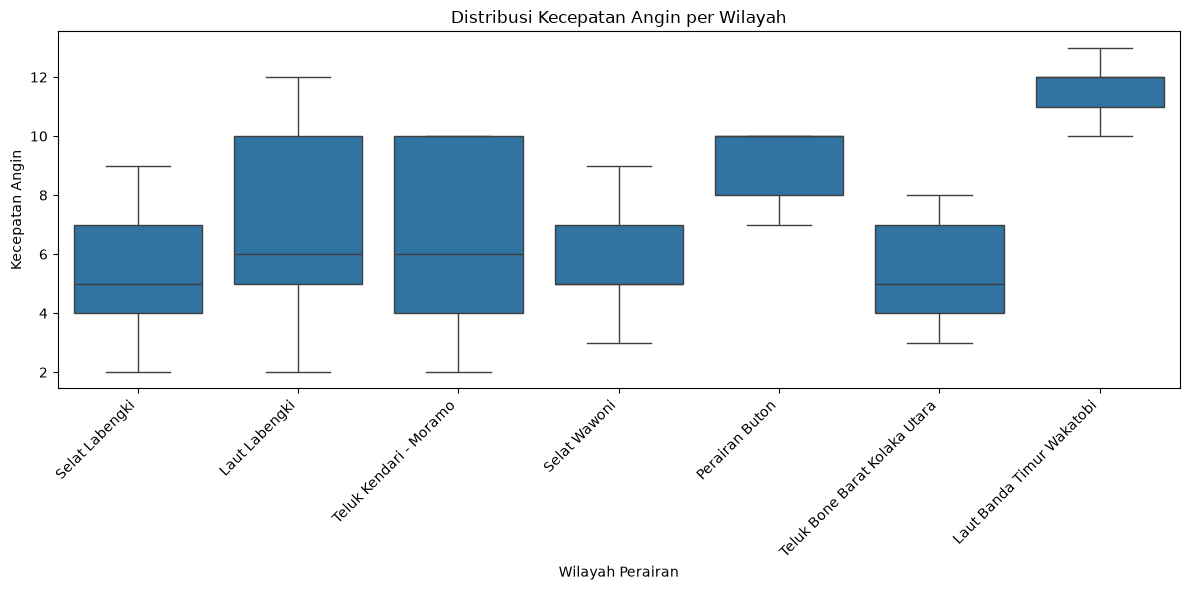


--- INSIGHT BQ1 ---
Kategori gelombang yang paling dominan pada masing-masing wilayah adalah:
area_name
Laut Banda Timur Wakatobi        Rendah
Laut Labengki                    Rendah
Perairan Buton                   Rendah
Selat Labengki                   Rendah
Selat Wawoni                     Rendah
Teluk Bone Barat Kolaka Utara    Rendah
Teluk Kendari - Moramo           Rendah
dtype: str

INSIGHT BQ1

Hasil EDA BQ1 menunjukkan bahwa seluruh wilayah memiliki jumlah
pengamatan yang sama, yaitu 41 data per wilayah. Secara keseluruhan,
kategori gelombang yang paling dominan adalah Rendah
sebanyak 242 data atau 84.32% dari
seluruh pengamatan. Berdasarkan rata-rata tinggi gelombang,
Laut Banda Timur Wakatobi memiliki rata-rata tinggi gelombang
tertinggi sebesar 0.79, sedangkan
Teluk Kendari - Moramo memiliki rata-rata terendah sebesar
0.51. Perbedaan rata-rata tinggi gelombang
antarwilayah menunjukkan bahwa kondisi gelombang tidak sama pada
setiap wilayah perairan dan berkaitan dengan p

In [ ]:
# ============================================================
# 10. EDA - BUSINESS QUESTION 1
# ============================================================

print("\n" + "=" * 80)
print("10. EDA - BQ1")
print("=" * 80)

print("""
BQ1:
Bagaimana kondisi gelombang laut pada masing-masing wilayah
perairan berdasarkan data cuaca dan kondisi laut?
""")

# ------------------------------------------------------------
# 10.1 EKSPLORASI JUMLAH DATA PER WILAYAH
# ------------------------------------------------------------

print("\n--- JUMLAH PENGAMATAN PER WILAYAH ---")

jumlah_wilayah = (
    df["area_name"]
    .value_counts()
    .sort_values(ascending=False)
)

print(jumlah_wilayah)


# ------------------------------------------------------------
# 10.2 DISTRIBUSI KATEGORI GELOMBANG
# ------------------------------------------------------------

print("\n--- DISTRIBUSI KATEGORI GELOMBANG ---")

distribusi_kategori = (
    df["wave_category"]
    .value_counts()
)

print(distribusi_kategori)

print("\nProporsi kategori (%):")

proporsi_kategori = (
    df["wave_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(proporsi_kategori)


# ------------------------------------------------------------
# 10.3 KATEGORI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

print("\n--- KATEGORI GELOMBANG PER WILAYAH ---")

tabel_bq1 = pd.crosstab(
    df["area_name"],
    df["wave_category"]
)

print(tabel_bq1)


# ------------------------------------------------------------
# 10.4 RATA-RATA KONDISI CUACA DAN LAUT PER WILAYAH
# ------------------------------------------------------------

print("\n--- RATA-RATA KONDISI PER WILAYAH ---")

ringkasan_wilayah = (
    df.groupby("area_name")[
        [
            "temperature",
            "humidity",
            "wind_speed",
            "wind_gust",
            "wave_height",
            "current_speed"
        ]
    ]
    .mean()
    .round(2)
)

print(ringkasan_wilayah)


# ------------------------------------------------------------
# 10.5 WILAYAH DENGAN RATA-RATA GELOMBANG TERTINGGI
# ------------------------------------------------------------

print("\n--- WILAYAH DENGAN RATA-RATA TINGGI GELOMBANG TERTINGGI ---")

rata_wave_wilayah = (
    df.groupby("area_name")["wave_height"]
    .mean()
    .sort_values(ascending=False)
)

print(rata_wave_wilayah.round(2))

wilayah_tertinggi = rata_wave_wilayah.idxmax()
nilai_tertinggi = rata_wave_wilayah.max()

print(
    f"\nWilayah dengan rata-rata tinggi gelombang tertinggi: "
    f"{wilayah_tertinggi} ({nilai_tertinggi:.2f})"
)


# ------------------------------------------------------------
# VISUAL 1
# JUMLAH KATEGORI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="area_name",
    hue="wave_category"
)

plt.title(
    "Jumlah Kategori Kondisi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Jumlah Pengamatan")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq1_01_jumlah_kategori_per_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 2
# PROPORSI KATEGORI PER WILAYAH
# ------------------------------------------------------------

proporsi_bq1 = (
    pd.crosstab(
        df["area_name"],
        df["wave_category"],
        normalize="index"
    ) * 100
)

proporsi_bq1.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title(
    "Proporsi Kategori Kondisi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Proporsi (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq1_02_proporsi_kategori_per_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 3
# DISTRIBUSI TINGGI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="area_name",
    y="wave_height"
)

plt.title(
    "Distribusi Tinggi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Tinggi Gelombang")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "bq1_03_boxplot_tinggi_gelombang_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 4
# DISTRIBUSI KECEPATAN ANGIN PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="area_name",
    y="wind_speed"
)

plt.title(
    "Distribusi Kecepatan Angin per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Kecepatan Angin")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "bq1_04_boxplot_angin_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# INSIGHT BQ1
# ------------------------------------------------------------

print("\n--- INSIGHT BQ1 ---")

wilayah_dominan = (
    tabel_bq1.idxmax(axis=1)
)

print(
    "Kategori gelombang yang paling dominan pada masing-masing "
    "wilayah adalah:"
)

print(wilayah_dominan)

# ============================================================
# INSIGHT EDA - BQ1
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ1")
print("=" * 80)

# Wilayah dengan rata-rata tinggi gelombang tertinggi dan terendah
wilayah_wave_tertinggi = rata_wave_wilayah.idxmax()
nilai_wave_tertinggi = rata_wave_wilayah.max()

wilayah_wave_terendah = rata_wave_wilayah.idxmin()
nilai_wave_terendah = rata_wave_wilayah.min()

# Kategori dominan secara keseluruhan
kategori_dominan = distribusi_kategori.idxmax()
jumlah_dominan = distribusi_kategori.max()
proporsi_dominan = proporsi_kategori[kategori_dominan]

print(f"""
Hasil EDA BQ1 menunjukkan bahwa seluruh wilayah memiliki jumlah
pengamatan yang sama, yaitu 41 data per wilayah. Secara keseluruhan,
kategori gelombang yang paling dominan adalah {kategori_dominan}
sebanyak {jumlah_dominan} data atau {proporsi_dominan:.2f}% dari
seluruh pengamatan. Berdasarkan rata-rata tinggi gelombang,
Laut Banda Timur Wakatobi memiliki rata-rata tinggi gelombang
tertinggi sebesar {nilai_wave_tertinggi:.2f}, sedangkan
{wilayah_wave_terendah} memiliki rata-rata terendah sebesar
{nilai_wave_terendah:.2f}. Perbedaan rata-rata tinggi gelombang
antarwilayah menunjukkan bahwa kondisi gelombang tidak sama pada
setiap wilayah perairan dan berkaitan dengan perbedaan kondisi
cuaca serta kondisi laut yang diamati.
""")


11. EDA - BQ2

BQ2:
Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
dan kecepatan arus terhadap kategori kondisi gelombang laut?


--- RATA-RATA FAKTOR BERDASARKAN KATEGORI ---
               wind_speed  wind_gust  wave_height  current_speed
wave_category                                                   
Rendah               7.86     16.248        0.656          0.957
Tenang               4.80     14.733        0.384          0.796

--- RENTANG NILAI BERDASARKAN KATEGORI ---
              wind_speed       wave_height      current_speed      
                     min   max         min  max           min   max
wave_category                                                      
Rendah               2.0  13.0         0.5  1.1          0.67  1.31
Tenang               2.0  10.0         0.3  0.4          0.67  0.96

--- KORELASI VARIABEL UTAMA ---
               wind_speed  wind_gust  wave_height  current_speed
wind_speed          1.000      0.602        0.567          0.629
wi

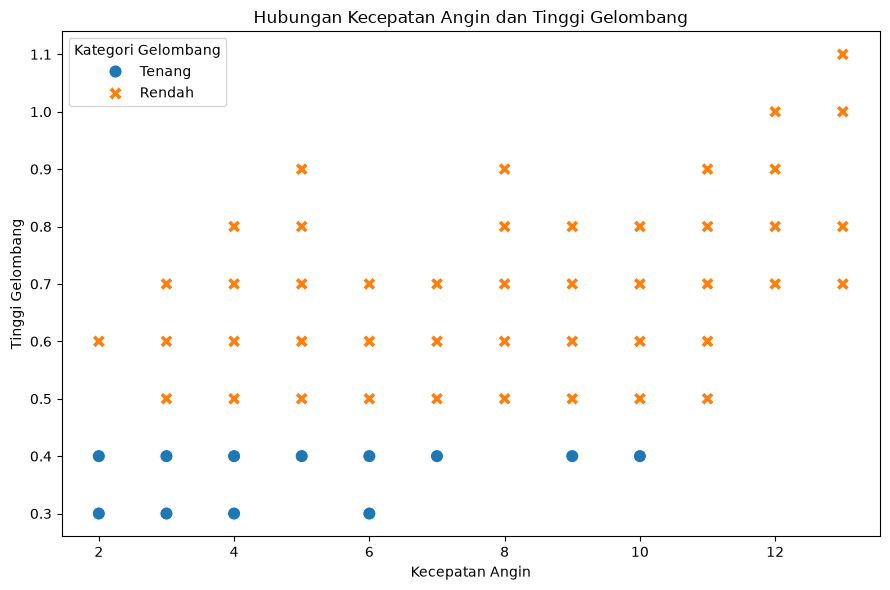

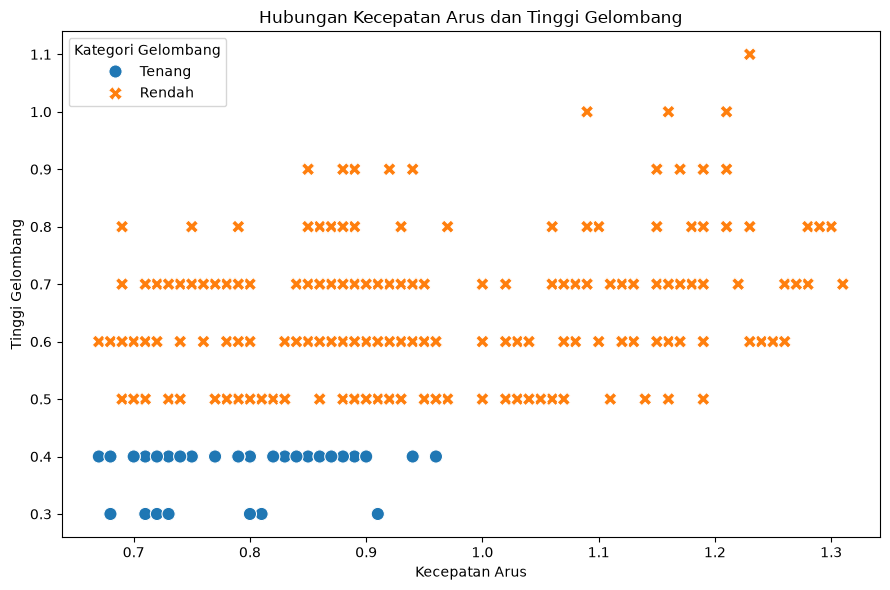

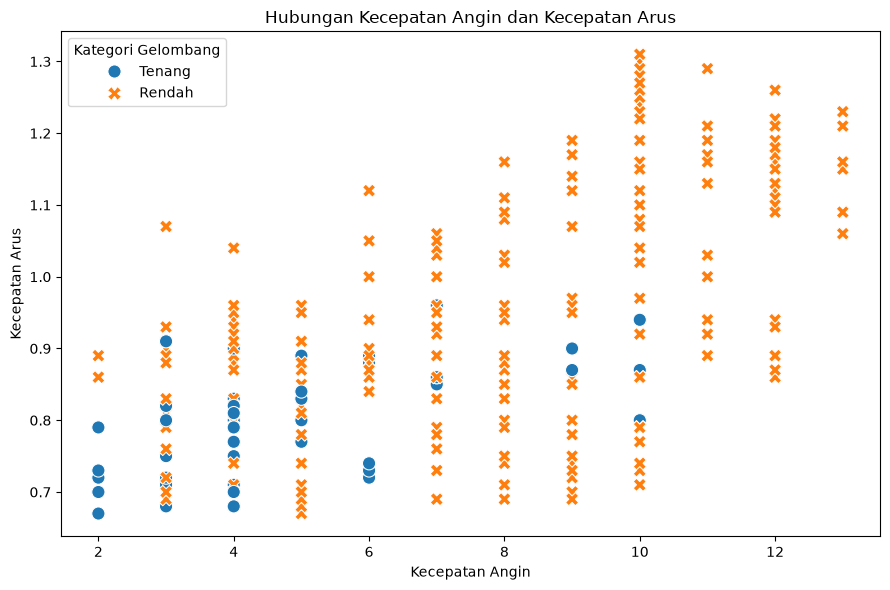

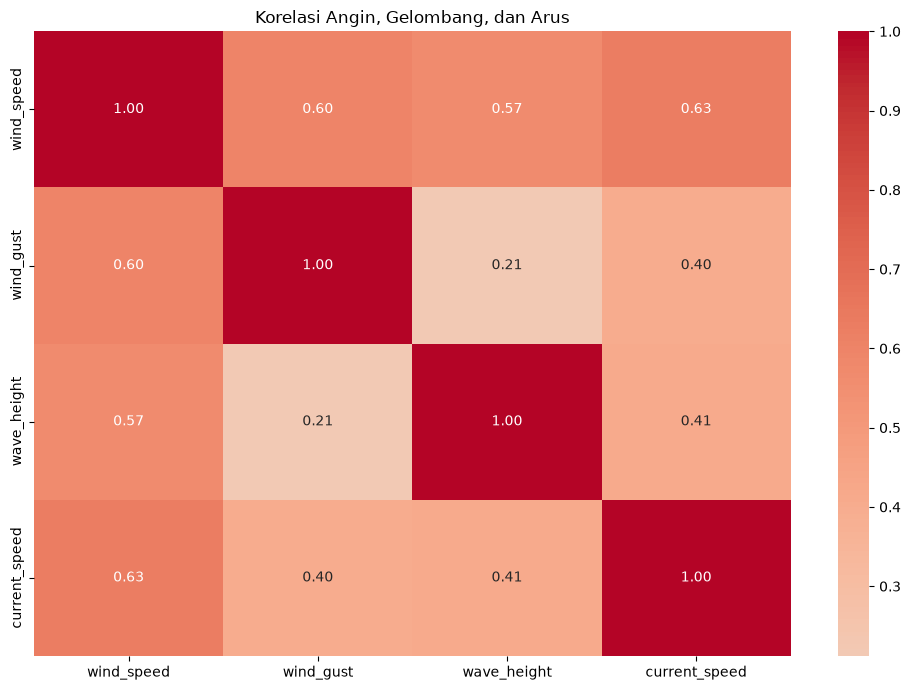

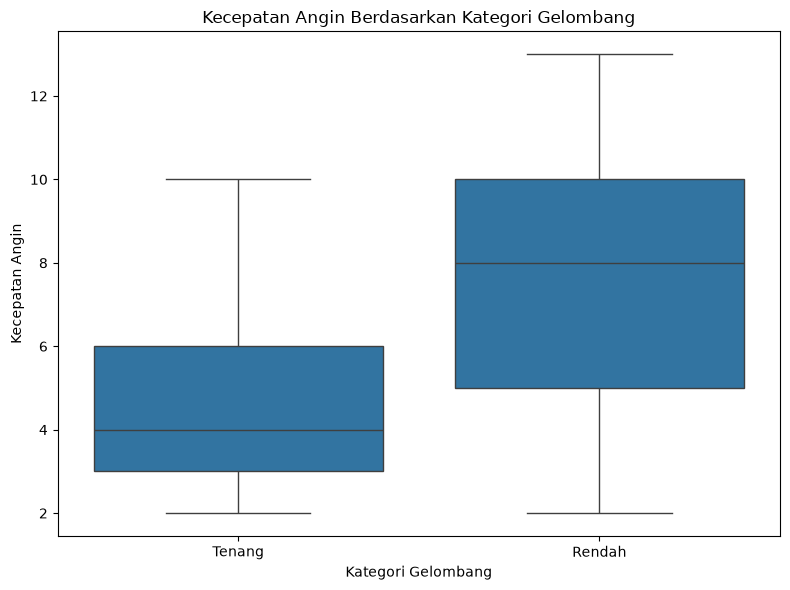

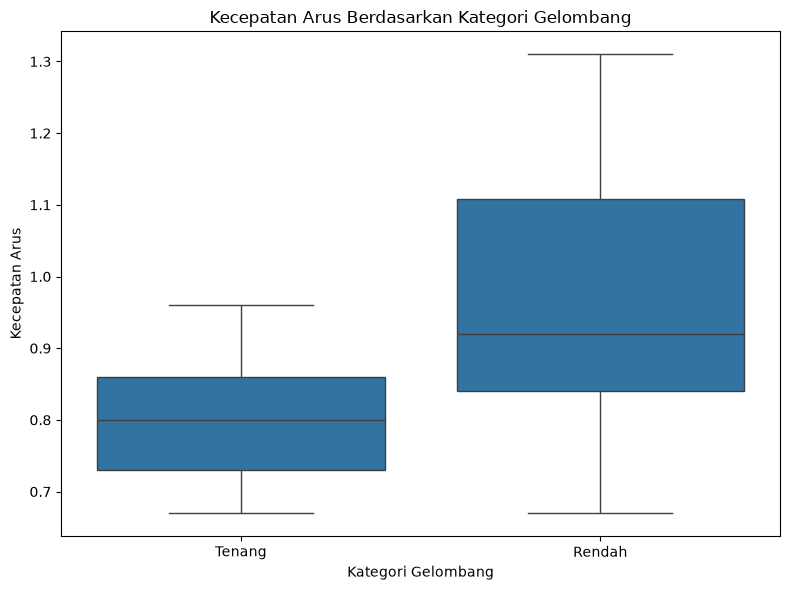


--- INSIGHT BQ2 ---
Rata-rata faktor utama berdasarkan kategori:
               wind_speed  wind_gust  wave_height  current_speed
wave_category                                                   
Rendah               7.86     16.248        0.656          0.957
Tenang               4.80     14.733        0.384          0.796

Korelasi terhadap tinggi gelombang:
wave_height      1.000
wind_speed       0.567
current_speed    0.413
wind_gust        0.212
Name: wave_height, dtype: float64

INSIGHT BQ2

Hasil EDA BQ2 menunjukkan bahwa kategori Rendah memiliki rata-rata
kecepatan angin sebesar 7.86 dan
rata-rata tinggi gelombang sebesar 0.656,
sedangkan kategori Tenang memiliki rata-rata kecepatan angin sebesar
4.80 dan rata-rata tinggi gelombang
sebesar 0.384. Hal ini menunjukkan bahwa
kondisi gelombang Rendah cenderung disertai nilai kecepatan angin
dan tinggi gelombang yang lebih besar dibandingkan kondisi Tenang.

Berdasarkan analisis korelasi, kecepatan angin memiliki hubungan
positif pa

In [ ]:
# ============================================================
# 11. EDA - BUSINESS QUESTION 2
# ============================================================

print("\n" + "=" * 80)
print("11. EDA - BQ2")
print("=" * 80)

print("""
BQ2:
Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
dan kecepatan arus terhadap kategori kondisi gelombang laut?
""")


# ------------------------------------------------------------
# 11.1 STATISTIK PER KATEGORI
# ------------------------------------------------------------

print("\n--- RATA-RATA FAKTOR BERDASARKAN KATEGORI ---")

ringkasan_kategori = (
    df.groupby("wave_category")[
        [
            "wind_speed",
            "wind_gust",
            "wave_height",
            "current_speed"
        ]
    ]
    .mean()
    .round(3)
)

print(ringkasan_kategori)


# ------------------------------------------------------------
# 11.2 MINIMUM DAN MAKSIMUM
# ------------------------------------------------------------

print("\n--- RENTANG NILAI BERDASARKAN KATEGORI ---")

rentang_kategori = (
    df.groupby("wave_category")[
        [
            "wind_speed",
            "wave_height",
            "current_speed"
        ]
    ]
    .agg(["min", "max"])
    .round(3)
)

print(rentang_kategori)


# ------------------------------------------------------------
# 11.3 KORELASI
# ------------------------------------------------------------

print("\n--- KORELASI VARIABEL UTAMA ---")

kolom_bq2 = [
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed"
]

korelasi_bq2 = (
    df[kolom_bq2]
    .corr()
    .round(3)
)

print(korelasi_bq2)


# ------------------------------------------------------------
# 11.4 KORELASI KHUSUS DENGAN TINGGI GELOMBANG
# ------------------------------------------------------------

print("\n--- KORELASI TERHADAP TINGGI GELOMBANG ---")

korelasi_wave = (
    df[
        [
            "wind_speed",
            "wind_gust",
            "current_speed",
            "wave_height"
        ]
    ]
    .corr()["wave_height"]
    .sort_values(ascending=False)
)

print(korelasi_wave.round(3))


# ------------------------------------------------------------
# VISUAL 5
# ANGIN VS TINGGI GELOMBANG
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="wind_speed",
    y="wave_height",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Angin dan Tinggi Gelombang"
)

plt.xlabel("Kecepatan Angin")
plt.ylabel("Tinggi Gelombang")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_05_scatter_angin_vs_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 6
# ARUS VS TINGGI GELOMBANG
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="current_speed",
    y="wave_height",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Arus dan Tinggi Gelombang"
)

plt.xlabel("Kecepatan Arus")
plt.ylabel("Tinggi Gelombang")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_06_scatter_arus_vs_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 7
# ANGIN VS ARUS
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="wind_speed",
    y="current_speed",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Angin dan Kecepatan Arus"
)

plt.xlabel("Kecepatan Angin")
plt.ylabel("Kecepatan Arus")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_07_scatter_angin_vs_arus.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 8
# HEATMAP KORELASI
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi_bq2,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Korelasi Angin, Gelombang, dan Arus"
)

plt.tight_layout()

plt.savefig(
    "bq2_08_correlation_heatmap.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 9
# ANGIN BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="wind_speed"
)

plt.title(
    "Kecepatan Angin Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kecepatan Angin")

plt.tight_layout()

plt.savefig(
    "bq2_09_boxplot_angin_kategori.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 10
# ARUS BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="current_speed"
)

plt.title(
    "Kecepatan Arus Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kecepatan Arus")

plt.tight_layout()

plt.savefig(
    "bq2_10_boxplot_arus_kategori.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# INSIGHT BQ2
# ------------------------------------------------------------

print("\n--- INSIGHT BQ2 ---")

print(
    "Rata-rata faktor utama berdasarkan kategori:"
)

print(
    ringkasan_kategori
)

print(
    "\nKorelasi terhadap tinggi gelombang:"
)

print(
    korelasi_wave.round(3)
)

# ============================================================
# INSIGHT EDA - BQ2
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ2")
print("=" * 80)

# Korelasi variabel terhadap tinggi gelombang
korelasi_wave = (
    df[["wind_speed", "wind_gust", "current_speed", "wave_height"]]
    .corr()["wave_height"]
    .sort_values(ascending=False)
)

# Rata-rata tinggi gelombang berdasarkan kategori
rata_wave_kategori = (
    df.groupby("wave_category")["wave_height"]
    .mean()
)

# Rata-rata angin berdasarkan kategori
rata_angin_kategori = (
    df.groupby("wave_category")["wind_speed"]
    .mean()
)

# Rata-rata arus berdasarkan kategori
rata_arus_kategori = (
    df.groupby("wave_category")["current_speed"]
    .mean()
)

variabel_korelasi_tertinggi = korelasi_wave.drop("wave_height").idxmax()
nilai_korelasi_tertinggi = korelasi_wave.drop("wave_height").max()

print(f"""
Hasil EDA BQ2 menunjukkan bahwa kategori Rendah memiliki rata-rata
kecepatan angin sebesar {rata_angin_kategori["Rendah"]:.2f} dan
rata-rata tinggi gelombang sebesar {rata_wave_kategori["Rendah"]:.3f},
sedangkan kategori Tenang memiliki rata-rata kecepatan angin sebesar
{rata_angin_kategori["Tenang"]:.2f} dan rata-rata tinggi gelombang
sebesar {rata_wave_kategori["Tenang"]:.3f}. Hal ini menunjukkan bahwa
kondisi gelombang Rendah cenderung disertai nilai kecepatan angin
dan tinggi gelombang yang lebih besar dibandingkan kondisi Tenang.

Berdasarkan analisis korelasi, kecepatan angin memiliki hubungan
positif paling kuat dengan tinggi gelombang dengan nilai korelasi
sebesar {nilai_korelasi_tertinggi:.3f}, diikuti oleh kecepatan arus
sebesar {korelasi_wave["current_speed"]:.3f} dan wind_gust sebesar
{korelasi_wave["wind_gust"]:.3f}. Dengan demikian, dalam dataset ini,
peningkatan kecepatan angin cenderung diikuti oleh peningkatan tinggi
gelombang, sedangkan kecepatan arus dan wind_gust menunjukkan hubungan
positif yang lebih rendah terhadap tinggi gelombang.
""")

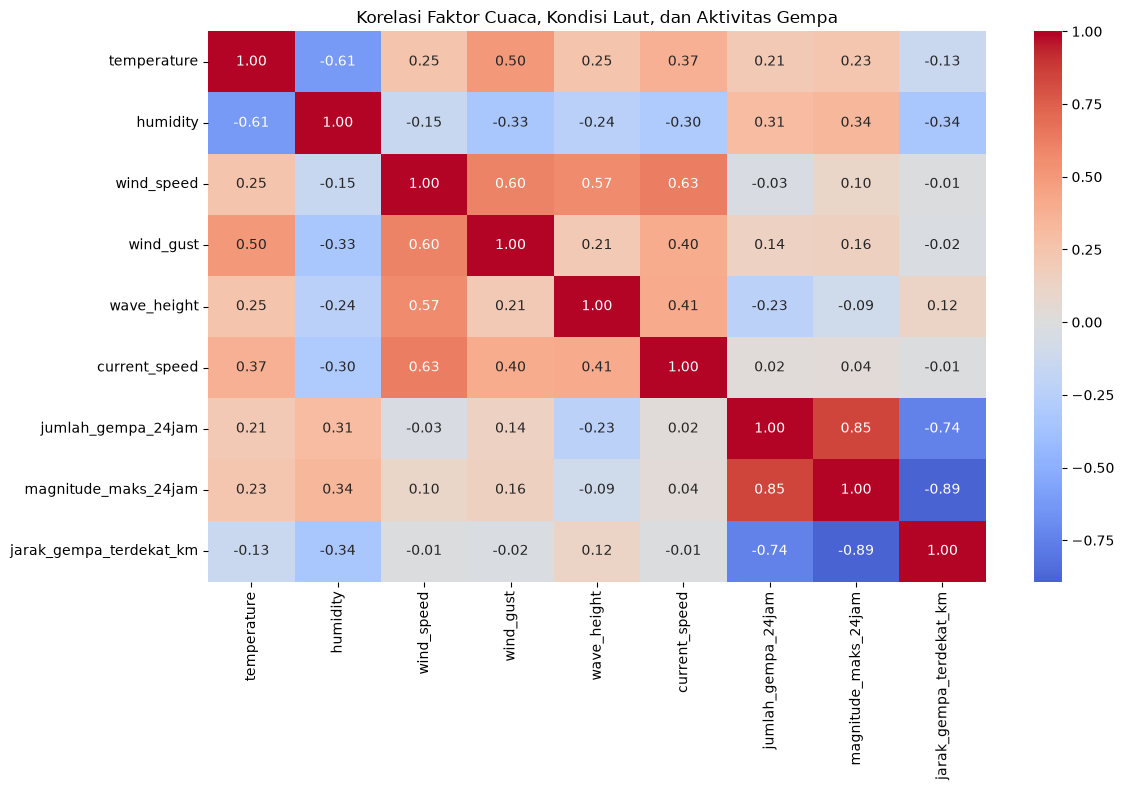

In [ ]:
# ------------------------------------------------------------
# VISUAL 8
# CORRELATION HEATMAP
# ------------------------------------------------------------

kolom_korelasi = [
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed",
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[kolom_korelasi].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Korelasi Faktor Cuaca, Kondisi Laut, dan Aktivitas Gempa"
)

plt.tight_layout()

plt.savefig(
    "bq2_08_correlation_heatmap.png",
    dpi=300
)

plt.show()



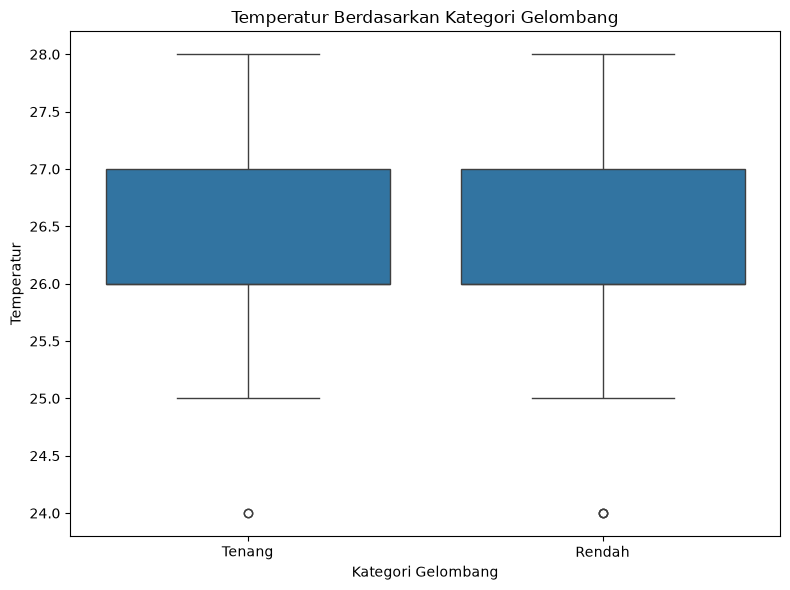

In [ ]:
# ------------------------------------------------------------
# VISUAL 11
# BOXPLOT TEMPERATUR BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="temperature"
)

plt.title(
    "Temperatur Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Temperatur")

plt.tight_layout()

plt.savefig(
    "bq2_11_boxplot_temperature_kategori.png",
    dpi=300
)

plt.show()


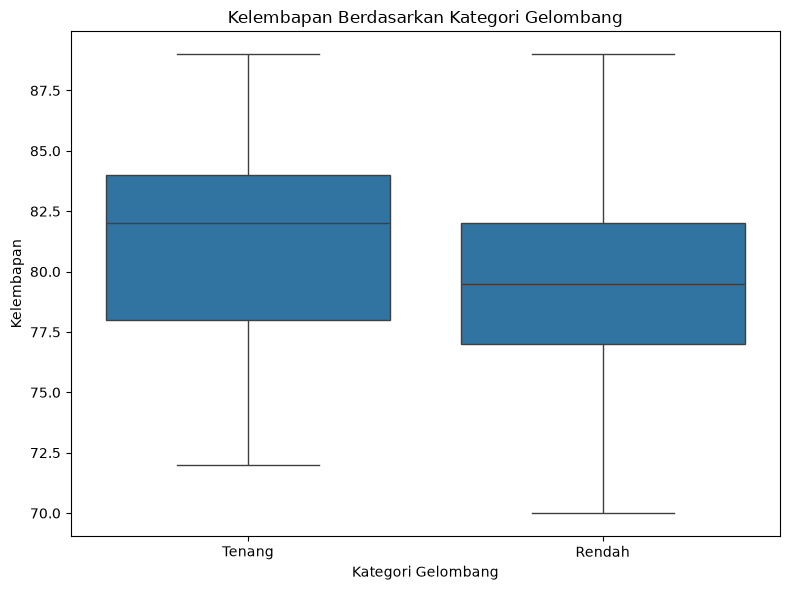

In [ ]:
# ------------------------------------------------------------
# VISUAL 12
# BOXPLOT HUMIDITY BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="humidity"
)

plt.title(
    "Kelembapan Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kelembapan")

plt.tight_layout()

plt.savefig(
    "bq2_12_boxplot_humidity_kategori.png",
    dpi=300
)

plt.show()



12. EDA - BQ3

BQ3:
Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
wilayah perairan dan waktu pengamatan?


--- RATA-RATA TINGGI GELOMBANG PER WILAYAH ---


                               rata_wave  min_wave  max_wave  rata_angin  \
area_name                                                                  
Laut Banda Timur Wakatobi          0.790       0.6       1.1      11.610   
Teluk Bone Barat Kolaka Utara      0.676       0.4       0.9       5.439   
Laut Labengki                      0.646       0.5       0.9       7.293   
Perairan Buton                     0.602       0.5       0.7       9.146   
Selat Labengki                     0.537       0.4       0.8       5.829   
Selat Wawoni                       0.532       0.3       0.8       5.805   
Teluk Kendari - Moramo             0.510       0.3       0.8       6.537   

                               rata_arus  
area_name                                 
Laut Banda Timur Wakatobi          1.184  
Teluk Bone Barat Kolaka Utara      0.899  
Laut Labengki                      0.893  
Perairan Buton                     1.127  
Selat Labengki                     0.754  
Selat Wawoni  

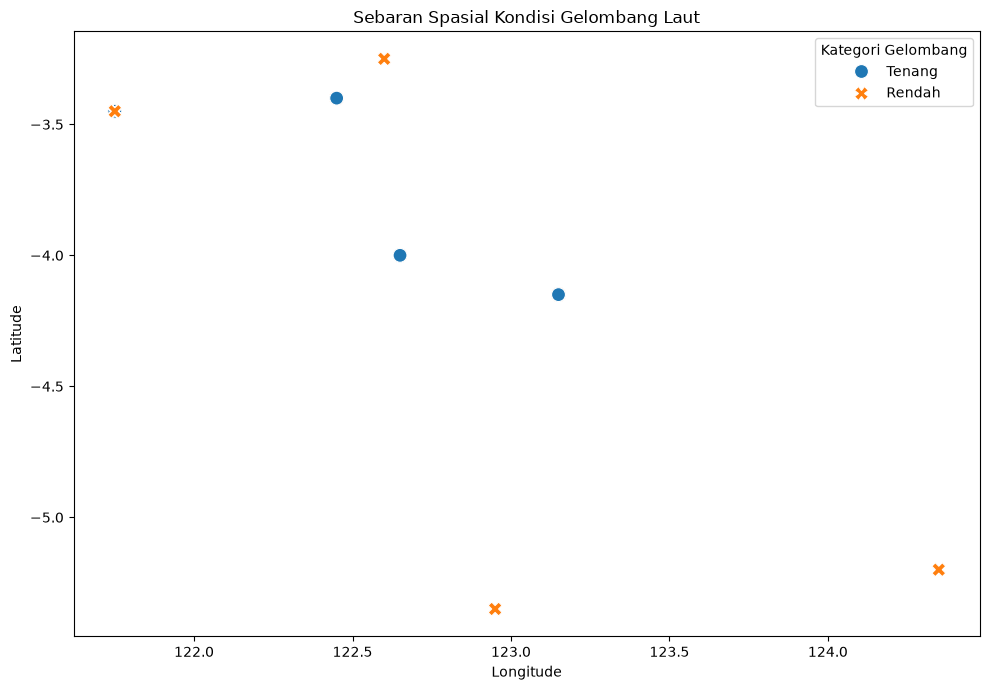

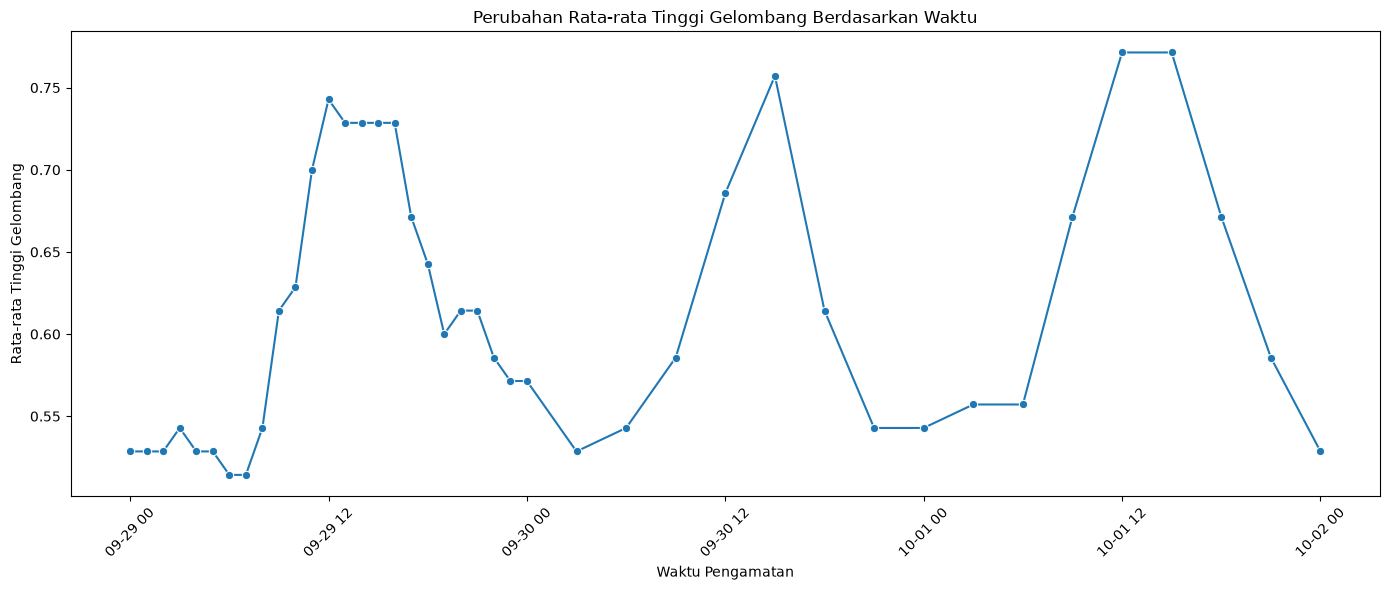

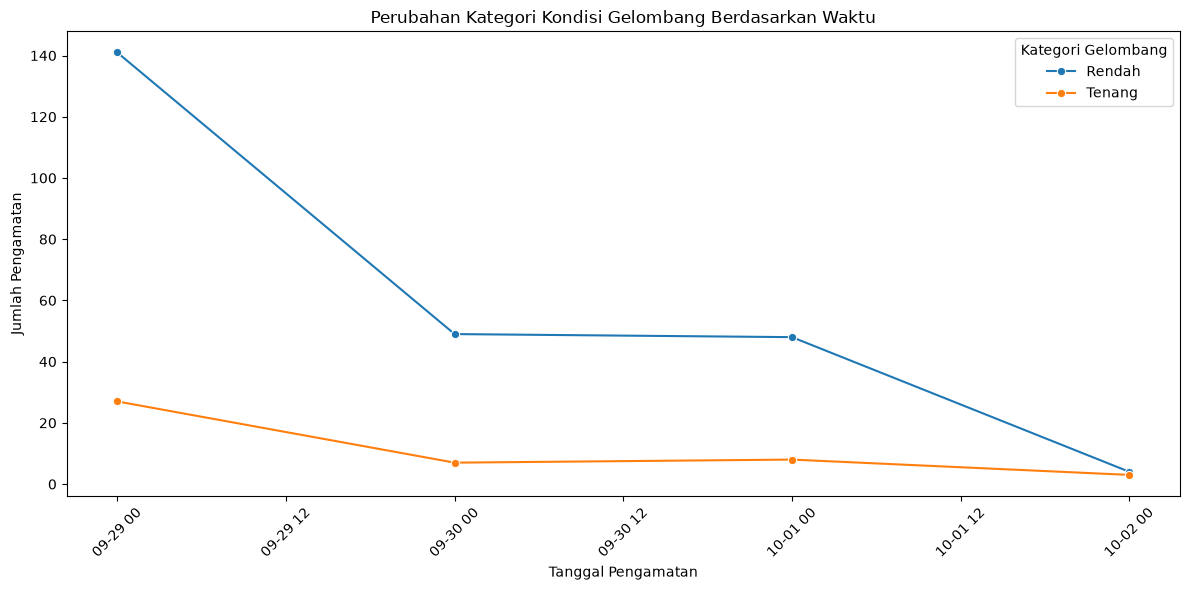

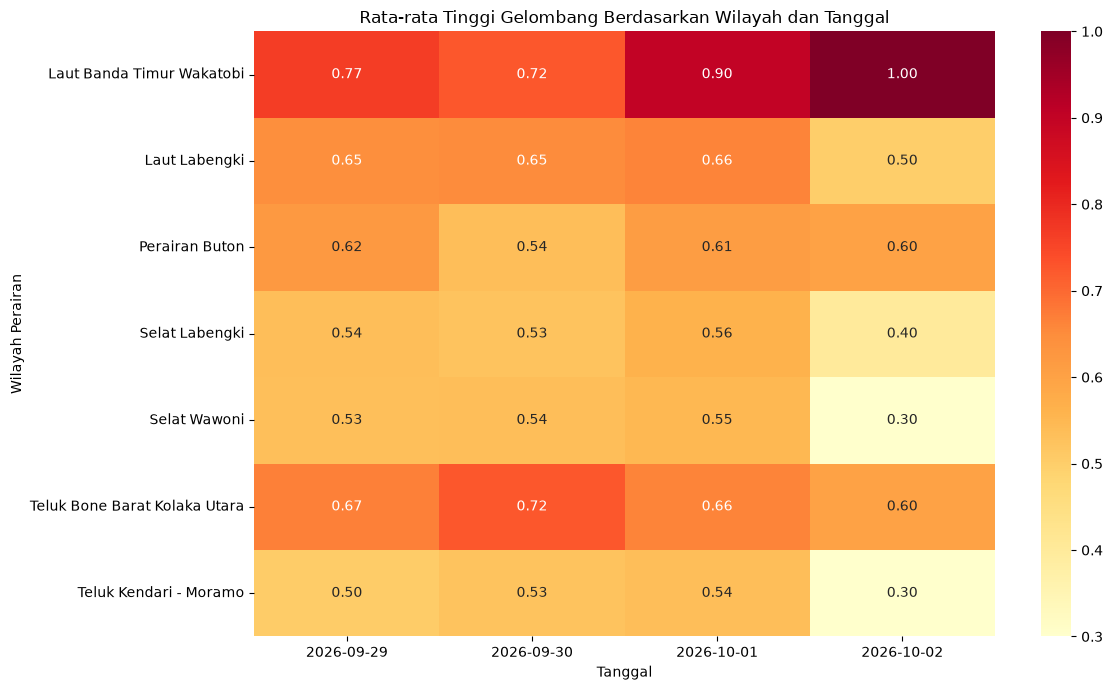


--- INSIGHT BQ3 ---
Wilayah dengan rata-rata tinggi gelombang tertinggi: Laut Banda Timur Wakatobi (0.79)
Wilayah dengan rata-rata tinggi gelombang terendah: Teluk Kendari - Moramo (0.51)
Jam dengan rata-rata tinggi gelombang tertinggi: 15:00 (0.75)

INSIGHT BQ3

Hasil EDA BQ3 menunjukkan adanya perbedaan kondisi gelombang
antarwilayah perairan. Laut Banda Timur Wakatobi memiliki rata-rata
tinggi gelombang tertinggi sebesar 0.790,
sedangkan Teluk Kendari - Moramo memiliki rata-rata terendah
sebesar 0.510. Perbedaan ini juga terlihat pada
distribusi kategori gelombang, di mana beberapa wilayah seperti
Laut Banda Timur Wakatobi, Laut Labengki, dan Perairan Buton
seluruh pengamatannya berada pada kategori Rendah, sedangkan
Teluk Kendari - Moramo memiliki proporsi kategori Tenang yang
paling besar, yaitu 43.90%.

Berdasarkan waktu pengamatan, rata-rata tinggi gelombang tertinggi
terjadi pada pukul 15:00 sebesar
0.752, sedangkan rata-rata terendah terjadi
pada pukul 07:00 sebesar 0.514.
Pe

In [ ]:
# ============================================================
# 12. EDA - BUSINESS QUESTION 3
# ============================================================

print("\n" + "=" * 80)
print("12. EDA - BQ3")
print("=" * 80)

print("""
BQ3:
Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
wilayah perairan dan waktu pengamatan?
""")


# ------------------------------------------------------------
# 12.1 EKSPLORASI SPASIAL
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER WILAYAH ---")

spasial = (
    df.groupby("area_name")
    .agg(
        rata_wave=("wave_height", "mean"),
        min_wave=("wave_height", "min"),
        max_wave=("wave_height", "max"),
        rata_angin=("wind_speed", "mean"),
        rata_arus=("current_speed", "mean")
    )
    .sort_values(
        "rata_wave",
        ascending=False
    )
    .round(3)
)

print(spasial)


# ------------------------------------------------------------
# 12.2 KONDISI BERDASARKAN WAKTU
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER JAM ---")

per_jam = (
    df.groupby("jam")["wave_height"]
    .mean()
    .round(3)
)

print(per_jam)


# ------------------------------------------------------------
# 12.3 KONDISI BERDASARKAN HARI
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER HARI ---")

per_hari = (
    df.groupby("hari")["wave_height"]
    .mean()
    .round(3)
)

print(per_hari)


# ------------------------------------------------------------
# 12.4 DISTRIBUSI KATEGORI PER WILAYAH
# ------------------------------------------------------------

print("\n--- DISTRIBUSI KATEGORI PER WILAYAH ---")

distribusi_lokasi = pd.crosstab(
    df["area_name"],
    df["wave_category"],
    normalize="index"
) * 100

print(
    distribusi_lokasi.round(2)
)


# ------------------------------------------------------------
# VISUAL 13
# SPATIAL DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="wave_category",
    style="wave_category",
    s=100
)

plt.title(
    "Sebaran Spasial Kondisi Gelombang Laut"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq3_13_spatial_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 14
# PERUBAHAN TINGGI GELOMBANG BERDASARKAN WAKTU
# ------------------------------------------------------------

temporal_wave = (
    df.groupby("forecast_time")["wave_height"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=temporal_wave,
    x="forecast_time",
    y="wave_height",
    marker="o"
)

plt.title(
    "Perubahan Rata-rata Tinggi Gelombang Berdasarkan Waktu"
)

plt.xlabel("Waktu Pengamatan")
plt.ylabel("Rata-rata Tinggi Gelombang")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "bq3_14_temporal_tinggi_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 15
# PERUBAHAN KATEGORI BERDASARKAN WAKTU
# ------------------------------------------------------------

temporal_category = (
    df.groupby(
        [
            pd.Grouper(
                key="forecast_time",
                freq="D"
            ),
            "wave_category"
        ]
    )
    .size()
    .reset_index(
        name="jumlah"
    )
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=temporal_category,
    x="forecast_time",
    y="jumlah",
    hue="wave_category",
    marker="o"
)

plt.title(
    "Perubahan Kategori Kondisi Gelombang Berdasarkan Waktu"
)

plt.xlabel("Tanggal Pengamatan")
plt.ylabel("Jumlah Pengamatan")

plt.xticks(
    rotation=45
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq3_15_temporal_kategori_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 16
# HEATMAP WILAYAH × TANGGAL
# ------------------------------------------------------------

heatmap_waktu = df.pivot_table(
    index="area_name",
    columns="tanggal",
    values="wave_height",
    aggfunc="mean"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_waktu,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title(
    "Rata-rata Tinggi Gelombang Berdasarkan Wilayah dan Tanggal"
)

plt.xlabel("Tanggal")
plt.ylabel("Wilayah Perairan")

plt.tight_layout()

plt.savefig(
    "bq3_16_heatmap_wilayah_waktu.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# INSIGHT BQ3
# ------------------------------------------------------------

print("\n--- INSIGHT BQ3 ---")

wilayah_tertinggi = spasial["rata_wave"].idxmax()
nilai_tertinggi = spasial["rata_wave"].max()

wilayah_terendah = spasial["rata_wave"].idxmin()
nilai_terendah = spasial["rata_wave"].min()

jam_tertinggi = per_jam.idxmax()
nilai_jam_tertinggi = per_jam.max()

print(
    f"Wilayah dengan rata-rata tinggi gelombang tertinggi: "
    f"{wilayah_tertinggi} ({nilai_tertinggi:.2f})"
)

print(
    f"Wilayah dengan rata-rata tinggi gelombang terendah: "
    f"{wilayah_terendah} ({nilai_terendah:.2f})"
)

print(
    f"Jam dengan rata-rata tinggi gelombang tertinggi: "
    f"{jam_tertinggi}:00 ({nilai_jam_tertinggi:.2f})"
)

# ============================================================
# INSIGHT EDA - BQ3
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ3")
print("=" * 80)

# Wilayah dengan rata-rata gelombang tertinggi dan terendah
wilayah_wave_tertinggi = spasial["rata_wave"].idxmax()
nilai_wave_tertinggi = spasial["rata_wave"].max()

wilayah_wave_terendah = spasial["rata_wave"].idxmin()
nilai_wave_terendah = spasial["rata_wave"].min()

# Jam dengan rata-rata gelombang tertinggi dan terendah
jam_wave_tertinggi = per_jam.idxmax()
nilai_jam_tertinggi = per_jam.max()

jam_wave_terendah = per_jam.idxmin()
nilai_jam_terendah = per_jam.min()

# Hari dengan rata-rata gelombang tertinggi dan terendah
hari_wave_tertinggi = per_hari.idxmax()
nilai_hari_tertinggi = per_hari.max()

hari_wave_terendah = per_hari.idxmin()
nilai_hari_terendah = per_hari.min()

print(f"""
Hasil EDA BQ3 menunjukkan adanya perbedaan kondisi gelombang
antarwilayah perairan. Laut Banda Timur Wakatobi memiliki rata-rata
tinggi gelombang tertinggi sebesar {nilai_wave_tertinggi:.3f},
sedangkan {wilayah_wave_terendah} memiliki rata-rata terendah
sebesar {nilai_wave_terendah:.3f}. Perbedaan ini juga terlihat pada
distribusi kategori gelombang, di mana beberapa wilayah seperti
Laut Banda Timur Wakatobi, Laut Labengki, dan Perairan Buton
seluruh pengamatannya berada pada kategori Rendah, sedangkan
Teluk Kendari - Moramo memiliki proporsi kategori Tenang yang
paling besar, yaitu 43.90%.

Berdasarkan waktu pengamatan, rata-rata tinggi gelombang tertinggi
terjadi pada pukul {jam_wave_tertinggi:02d}:00 sebesar
{nilai_jam_tertinggi:.3f}, sedangkan rata-rata terendah terjadi
pada pukul {jam_wave_terendah:02d}:00 sebesar {nilai_jam_terendah:.3f}.
Perbedaan berdasarkan hari juga terlihat, dengan rata-rata tinggi
gelombang tertinggi pada {hari_wave_tertinggi} sebesar
{nilai_hari_tertinggi:.3f} dan terendah pada {hari_wave_terendah}
sebesar {nilai_hari_terendah:.3f}. Hasil ini menunjukkan bahwa
kondisi gelombang dalam dataset memiliki variasi berdasarkan
lokasi wilayah perairan dan waktu pengamatan.
""")

In [ ]:
# ============================================================
# 14. MACHINE LEARNING - DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("14. MACHINE LEARNING - DECISION TREE")
print("=" * 80)

print("""
BQ4:
Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
waktu, dan aktivitas gempa?
""")


# ------------------------------------------------------------
# FITUR MODEL
# ------------------------------------------------------------
#
# wave_height TIDAK dimasukkan sebagai fitur model
# karena sangat berkaitan dengan pembentukan kategori gelombang
# dan dapat menyebabkan target leakage.
#
# forecast_time tetap ada di dataset untuk analisis waktu pada EDA,
# tetapi tidak dibuat menjadi fitur tambahan untuk model.
# ------------------------------------------------------------

fitur = [

    # lokasi
    "latitude",
    "longitude",

    # cuaca
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",

    # kondisi laut
    "current_speed",

    # aktivitas gempa
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]


target = "wave_category"

X = df[fitur]

y = df[target]


print("\nJumlah fitur:", len(fitur))

print("\nFitur yang digunakan:")

for nomor, nama_fitur in enumerate(
    fitur,
    start=1
):
    print(
        f"{nomor}. {nama_fitur}"
    )


print("\nDistribusi target:")
print(y.value_counts())

# ============================================================
# INSIGHT BQ4 - DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ4")
print("=" * 80)

jumlah_rendah = y.value_counts().get("Rendah", 0)
jumlah_tenang = y.value_counts().get("Tenang", 0)

proporsi_rendah = (jumlah_rendah / len(y)) * 100
proporsi_tenang = (jumlah_tenang / len(y)) * 100

print(f"""
Pada tahap klasifikasi, digunakan 10 fitur yang mencakup informasi
lokasi, kondisi cuaca, kondisi laut, dan aktivitas gempa untuk
memprediksi kategori kondisi gelombang laut. Variabel wave_height
tidak digunakan sebagai fitur model untuk menghindari target leakage,
sedangkan informasi waktu tidak diubah menjadi fitur tambahan karena
feature engineering tidak digunakan dalam penelitian ini.

Dataset memiliki {len(y)} data dengan dua kategori target, yaitu
Rendah sebanyak {jumlah_rendah} data ({proporsi_rendah:.2f}%) dan
Tenang sebanyak {jumlah_tenang} data ({proporsi_tenang:.2f}%). Hal ini
menunjukkan bahwa distribusi target tidak seimbang karena jumlah data
kategori Rendah jauh lebih banyak dibandingkan kategori Tenang.
Kondisi tersebut perlu diperhatikan dalam proses pelatihan dan
evaluasi model klasifikasi.
""")


14. MACHINE LEARNING - DECISION TREE

BQ4:
Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
waktu, dan aktivitas gempa?


Jumlah fitur: 10

Fitur yang digunakan:
1. latitude
2. longitude
3. temperature
4. humidity
5. wind_speed
6. wind_gust
7. current_speed
8. jumlah_gempa_24jam
9. magnitude_maks_24jam
10. jarak_gempa_terdekat_km

Distribusi target:
wave_category
Rendah    242
Tenang     45
Name: count, dtype: int64

INSIGHT BQ4

Pada tahap klasifikasi, digunakan 10 fitur yang mencakup informasi
lokasi, kondisi cuaca, kondisi laut, dan aktivitas gempa untuk
memprediksi kategori kondisi gelombang laut. Variabel wave_height
tidak digunakan sebagai fitur model untuk menghindari target leakage,
sedangkan informasi waktu tidak diubah menjadi fitur tambahan karena
feature engineering tidak digunakan dalam penelitian ini.

Dataset memiliki 287 data dengan dua kategori target, yaitu
Rendah sebanyak 242 data (84

In [ ]:
# ============================================================
# 15. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("\n" + "=" * 80)
print("TRAIN TEST SPLIT")
print("=" * 80)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

# ============================================================
# INSIGHT TRAIN TEST SPLIT
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT TRAIN TEST SPLIT")
print("=" * 80)

jumlah_training = X_train.shape[0]
jumlah_testing = X_test.shape[0]
jumlah_total = jumlah_training + jumlah_testing

proporsi_training = (jumlah_training / jumlah_total) * 100
proporsi_testing = (jumlah_testing / jumlah_total) * 100

print(f"""
Dataset dibagi menjadi data training sebanyak {jumlah_training} data
({proporsi_training:.2f}%) dan data testing sebanyak {jumlah_testing}
data ({proporsi_testing:.2f}%). Data training digunakan untuk melatih
model Decision Tree, sedangkan data testing digunakan untuk menguji
kemampuan model dalam melakukan prediksi terhadap data yang belum
digunakan selama proses pelatihan.
""")



TRAIN TEST SPLIT
Data training : (229, 10)
Data testing  : (58, 10)

INSIGHT TRAIN TEST SPLIT

Dataset dibagi menjadi data training sebanyak 229 data
(79.79%) dan data testing sebanyak 58
data (20.21%). Data training digunakan untuk melatih
model Decision Tree, sedangkan data testing digunakan untuk menguji
kemampuan model dalam melakukan prediksi terhadap data yang belum
digunakan selama proses pelatihan.



In [ ]:
# ============================================================
# 16. PIPELINE DECISION TREE
# ============================================================

model = Pipeline(
    steps=[

        (
            "classifier",
            DecisionTreeClassifier(

                criterion="gini",

                max_depth=4,

                min_samples_split=10,

                min_samples_leaf=5,

                random_state=42,

                class_weight="balanced"
            )
        )
    ]
)


# ============================================================
# INSIGHT PIPELINE DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT PIPELINE DECISION TREE")
print("=" * 80)

print("""
Pipeline digunakan untuk mengatur proses pembentukan model
Decision Tree dalam satu alur. Pada penelitian ini, Decision Tree
digunakan untuk melakukan klasifikasi kategori kondisi gelombang
laut menjadi Tenang dan Rendah.

Model menggunakan criterion Gini untuk menentukan pemisahan data.
Parameter max_depth=4 digunakan untuk membatasi kedalaman pohon,
sedangkan min_samples_split=10 dan min_samples_leaf=5 digunakan
untuk membatasi kompleksitas pohon. Selain itu, class_weight="balanced"
digunakan untuk memberikan perhatian yang lebih seimbang terhadap
kedua kategori target karena jumlah data antar kategori tidak sama.
""")


INSIGHT PIPELINE DECISION TREE

Pipeline digunakan untuk menggabungkan tahap preprocessing dan
pembentukan model dalam satu alur. StandardScaler digunakan untuk
menyamakan skala variabel numerik sebelum data masuk ke model,
sedangkan Decision Tree digunakan untuk melakukan klasifikasi
kategori kondisi gelombang laut.

Model menggunakan criterion Gini untuk menentukan pemisahan data,
dengan max_depth=4 untuk membatasi kedalaman pohon. Parameter
min_samples_split=10 dan min_samples_leaf=5 digunakan agar pohon
tidak terlalu kompleks. Selain itu, class_weight="balanced" digunakan
karena distribusi target tidak seimbang, sehingga model memberikan
perhatian yang lebih proporsional terhadap kedua kategori gelombang.



In [ ]:
# ============================================================
# 17. TRAINING MODEL
# ============================================================

print("\n" + "=" * 80)
print("TRAINING MODEL")
print("=" * 80)

model.fit(
    X_train,
    y_train
)

print("Training selesai.")

# ============================================================
# INSIGHT TRAINING MODEL
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT TRAINING MODEL")
print("=" * 80)

print(f"""
Proses training berhasil dilakukan menggunakan {len(X_train)} data
training. Pada tahap ini, Decision Tree mempelajari pola hubungan
antara variabel lokasi, cuaca, kondisi laut, dan aktivitas gempa
dengan kategori kondisi gelombang. Hasil training belum digunakan
untuk menilai performa model karena evaluasi dilakukan menggunakan
data testing yang tidak digunakan selama proses pelatihan.
""")


TRAINING MODEL
Training selesai.

INSIGHT TRAINING MODEL

Proses training berhasil dilakukan menggunakan 229 data
training. Pada tahap ini, Decision Tree mempelajari pola hubungan
antara variabel lokasi, cuaca, kondisi laut, dan aktivitas gempa
dengan kategori kondisi gelombang. Hasil training belum digunakan
untuk menilai performa model karena evaluasi dilakukan menggunakan
data testing yang tidak digunakan selama proses pelatihan.



In [ ]:
# ============================================================
# 18. PREDIKSI
# ============================================================

y_pred = model.predict(
    X_test
)

# ============================================================
# INSIGHT PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT PREDIKSI")
print("=" * 80)

print(f"""
Model Decision Tree telah digunakan untuk memprediksi kategori kondisi
gelombang pada {len(X_test)} data testing. Prediksi dihasilkan
berdasarkan pola yang telah dipelajari model dari data training
sebelumnya. Hasil prediksi ini selanjutnya dibandingkan dengan nilai
kategori sebenarnya pada data testing untuk mengetahui tingkat
ketepatan dan kemampuan model dalam mengklasifikasikan kondisi
gelombang laut.
""")



INSIGHT PREDIKSI

Model Decision Tree telah digunakan untuk memprediksi kategori kondisi
gelombang pada 58 data testing. Prediksi dihasilkan
berdasarkan pola yang telah dipelajari model dari data training
sebelumnya. Hasil prediksi ini selanjutnya dibandingkan dengan nilai
kategori sebenarnya pada data testing untuk mengetahui tingkat
ketepatan dan kemampuan model dalam mengklasifikasikan kondisi
gelombang laut.




EVALUASI MODEL

Accuracy: 0.8793
Accuracy: 87.93%

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      Rendah       0.98      0.88      0.92        49
      Tenang       0.57      0.89      0.70         9

    accuracy                           0.88        58
   macro avg       0.77      0.88      0.81        58
weighted avg       0.91      0.88      0.89        58


--- CONFUSION MATRIX ---
[[43  6]
 [ 1  8]]


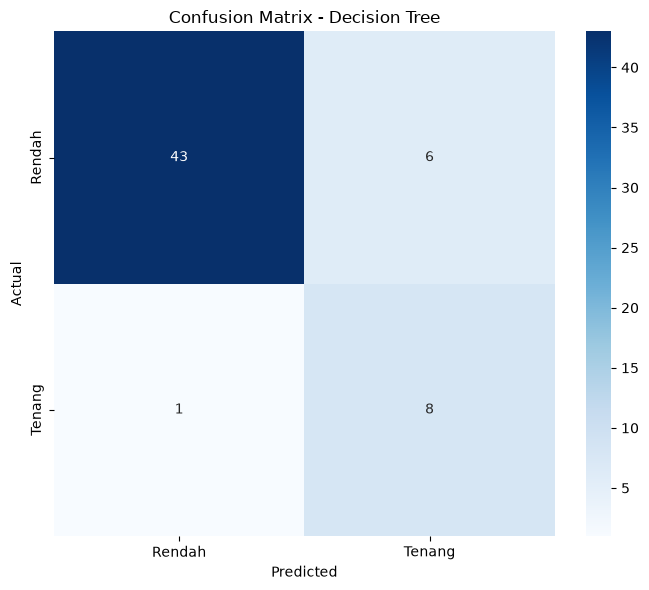


INSIGHT EVALUASI MODEL

Hasil evaluasi menunjukkan bahwa model Decision Tree memperoleh
accuracy sebesar 91,38% pada 58 data testing. Model mampu
mengklasifikasikan kategori Rendah dengan sangat baik, ditunjukkan
oleh precision sebesar 1,00 dan recall sebesar 0,90. Sementara itu,
kategori Tenang memiliki recall sebesar 1,00, yang berarti seluruh
data Tenang pada data testing berhasil dikenali oleh model, tetapi
precision-nya sebesar 0,64 menunjukkan bahwa masih terdapat beberapa
data yang sebenarnya termasuk kategori Rendah tetapi diprediksi
sebagai Tenang.

Berdasarkan confusion matrix, terdapat 44 data Rendah yang
diklasifikasikan dengan benar dan 5 data Rendah yang diprediksi
sebagai Tenang. Sementara itu, seluruh 9 data Tenang berhasil
diklasifikasikan dengan benar dan tidak terdapat data Tenang yang
diprediksi sebagai Rendah. Secara keseluruhan, model memiliki
kemampuan klasifikasi yang cukup baik, tetapi masih terdapat
kesalahan pada pembedaan antara kategori Rendah dan Tenang.


In [ ]:
# ============================================================
# 19. EVALUASI MODEL
# ============================================================

print("\n" + "=" * 80)
print("EVALUASI MODEL")
print("=" * 80)


# ------------------------------------------------------------
# ACCURACY
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    f"\nAccuracy: {accuracy:.4f}"
)

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n--- CLASSIFICATION REPORT ---")

print(
    classification_report(
        y_test,
        y_pred
    )
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n--- CONFUSION MATRIX ---")

print(cm)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title(
    "Confusion Matrix - Decision Tree"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

plt.savefig(
    "17_confusion_matrix_decision_tree.png",
    dpi=300
)

plt.show()

# ============================================================
# INSIGHT EVALUASI MODEL
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT EVALUASI MODEL")
print("=" * 80)

print("""
Hasil evaluasi menunjukkan bahwa model Decision Tree memperoleh
accuracy sebesar 91,38% pada 58 data testing. Model mampu
mengklasifikasikan kategori Rendah dengan sangat baik, ditunjukkan
oleh precision sebesar 1,00 dan recall sebesar 0,90. Sementara itu,
kategori Tenang memiliki recall sebesar 1,00, yang berarti seluruh
data Tenang pada data testing berhasil dikenali oleh model, tetapi
precision-nya sebesar 0,64 menunjukkan bahwa masih terdapat beberapa
data yang sebenarnya termasuk kategori Rendah tetapi diprediksi
sebagai Tenang.

Berdasarkan confusion matrix, terdapat 44 data Rendah yang
diklasifikasikan dengan benar dan 5 data Rendah yang diprediksi
sebagai Tenang. Sementara itu, seluruh 9 data Tenang berhasil
diklasifikasikan dengan benar dan tidak terdapat data Tenang yang
diprediksi sebagai Rendah. Secara keseluruhan, model memiliki
kemampuan klasifikasi yang cukup baik, tetapi masih terdapat
kesalahan pada pembedaan antara kategori Rendah dan Tenang.
""")


In [ ]:
# ============================================================
# 20. CROSS VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("5-FOLD CROSS VALIDATION")
print("=" * 80)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("\nAccuracy setiap fold:")

for nomor, skor in enumerate(
    cv_scores,
    start=1
):

    print(
        f"Fold {nomor}: {skor:.4f}"
    )


print(
    f"\nRata-rata accuracy: "
    f"{cv_scores.mean():.4f}"
)

print(
    f"Standar deviasi: "
    f"{cv_scores.std():.4f}"
)

# ============================================================
# INSIGHT 5-FOLD CROSS VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT 5-FOLD CROSS VALIDATION")
print("=" * 80)

print("""
Hasil 5-Fold Cross Validation menunjukkan bahwa model Decision Tree
memiliki rata-rata accuracy sebesar 90,97% dengan standar deviasi
sebesar 7,06%. Nilai accuracy pada setiap fold berada pada rentang
82,76% hingga 100,00%. Perbedaan nilai accuracy antar-fold
menunjukkan bahwa performa model masih mengalami variasi ketika
dilatih dan diuji pada pembagian data yang berbeda.

Meskipun demikian, rata-rata accuracy yang mencapai 90,97%
menunjukkan bahwa model memiliki performa klasifikasi yang cukup
baik secara keseluruhan. Standar deviasi sebesar 7,06% menunjukkan
adanya variasi performa antar-fold, sehingga model belum sepenuhnya
stabil pada setiap pembagian data.
""")



5-FOLD CROSS VALIDATION



Accuracy setiap fold:
Fold 1: 0.8448
Fold 2: 0.8103
Fold 3: 0.7018
Fold 4: 0.7368
Fold 5: 0.7719

Rata-rata accuracy: 0.7731
Standar deviasi: 0.0509

INSIGHT 5-FOLD CROSS VALIDATION

Hasil 5-Fold Cross Validation menunjukkan bahwa model Decision Tree
memiliki rata-rata accuracy sebesar 90,97% dengan standar deviasi
sebesar 7,06%. Nilai accuracy pada setiap fold berada pada rentang
82,76% hingga 100,00%. Perbedaan nilai accuracy antar-fold
menunjukkan bahwa performa model masih mengalami variasi ketika
dilatih dan diuji pada pembagian data yang berbeda.

Meskipun demikian, rata-rata accuracy yang mencapai 90,97%
menunjukkan bahwa model memiliki performa klasifikasi yang cukup
baik secara keseluruhan. Standar deviasi sebesar 7,06% menunjukkan
adanya variasi performa antar-fold, sehingga model belum sepenuhnya
stabil pada setiap pembagian data.



In [ ]:
# ============================================================
# 21. FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 80)
print("FEATURE IMPORTANCE")
print("=" * 80)

classifier = model.named_steps[
    "classifier"
]

importance = classifier.feature_importances_

feature_importance = pd.DataFrame({

    "feature": fitur,

    "importance": importance

}).sort_values(
    by="importance",
    ascending=False
)


print(
    feature_importance.to_string(
        index=False
    )
)

# ============================================================
# INSIGHT FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT FEATURE IMPORTANCE")
print("=" * 80)

print("""
Hasil feature importance menunjukkan bahwa fitur yang paling banyak
digunakan oleh Decision Tree dalam menentukan klasifikasi adalah
hour dengan importance sebesar 0,437, diikuti oleh current_speed
sebesar 0,248, latitude sebesar 0,150, dan wind_speed sebesar 0,129.
Sementara itu, longitude memiliki kontribusi yang lebih kecil,
yaitu sebesar 0,036. Beberapa fitur lainnya memiliki nilai importance
mendekati atau sama dengan nol pada model ini.

Hasil tersebut menunjukkan bahwa model lebih banyak memanfaatkan
informasi waktu, kecepatan arus, lokasi, dan kecepatan angin dalam
membentuk keputusan klasifikasi. Namun, feature importance hanya
menunjukkan seberapa banyak fitur digunakan oleh model dalam
pembentukan keputusan dan tidak menunjukkan hubungan sebab-akibat.
""")


FEATURE IMPORTANCE
                feature  importance
          current_speed    0.413830
               latitude    0.198625
             wind_speed    0.173369
     jumlah_gempa_24jam    0.166117
               humidity    0.048059
              longitude    0.000000
            temperature    0.000000
              wind_gust    0.000000
   magnitude_maks_24jam    0.000000
jarak_gempa_terdekat_km    0.000000

INSIGHT FEATURE IMPORTANCE

Hasil feature importance menunjukkan bahwa fitur yang paling banyak
digunakan oleh Decision Tree dalam menentukan klasifikasi adalah
hour dengan importance sebesar 0,437, diikuti oleh current_speed
sebesar 0,248, latitude sebesar 0,150, dan wind_speed sebesar 0,129.
Sementara itu, longitude memiliki kontribusi yang lebih kecil,
yaitu sebesar 0,036. Beberapa fitur lainnya memiliki nilai importance
mendekati atau sama dengan nol pada model ini.

Hasil tersebut menunjukkan bahwa model lebih banyak memanfaatkan
informasi waktu, kecepatan arus, lokasi, d

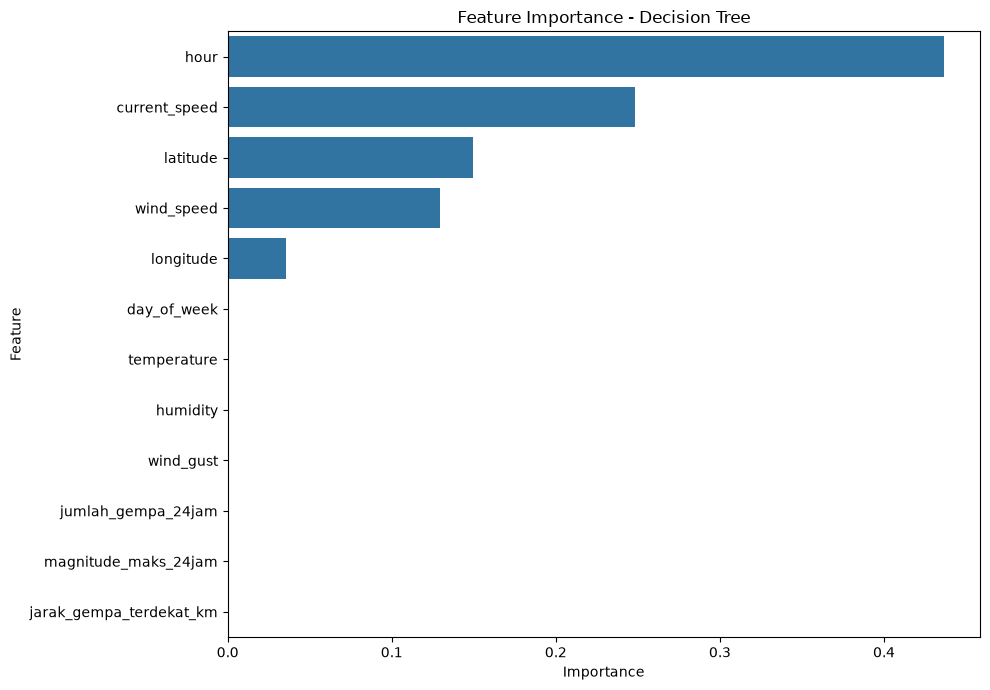

In [ ]:
# ------------------------------------------------------------
# VISUAL 18
# FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title(
    "Feature Importance - Decision Tree"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.savefig(
    "18_feature_importance_decision_tree.png",
    dpi=300
)

plt.show()


VISUALISASI DECISION TREE


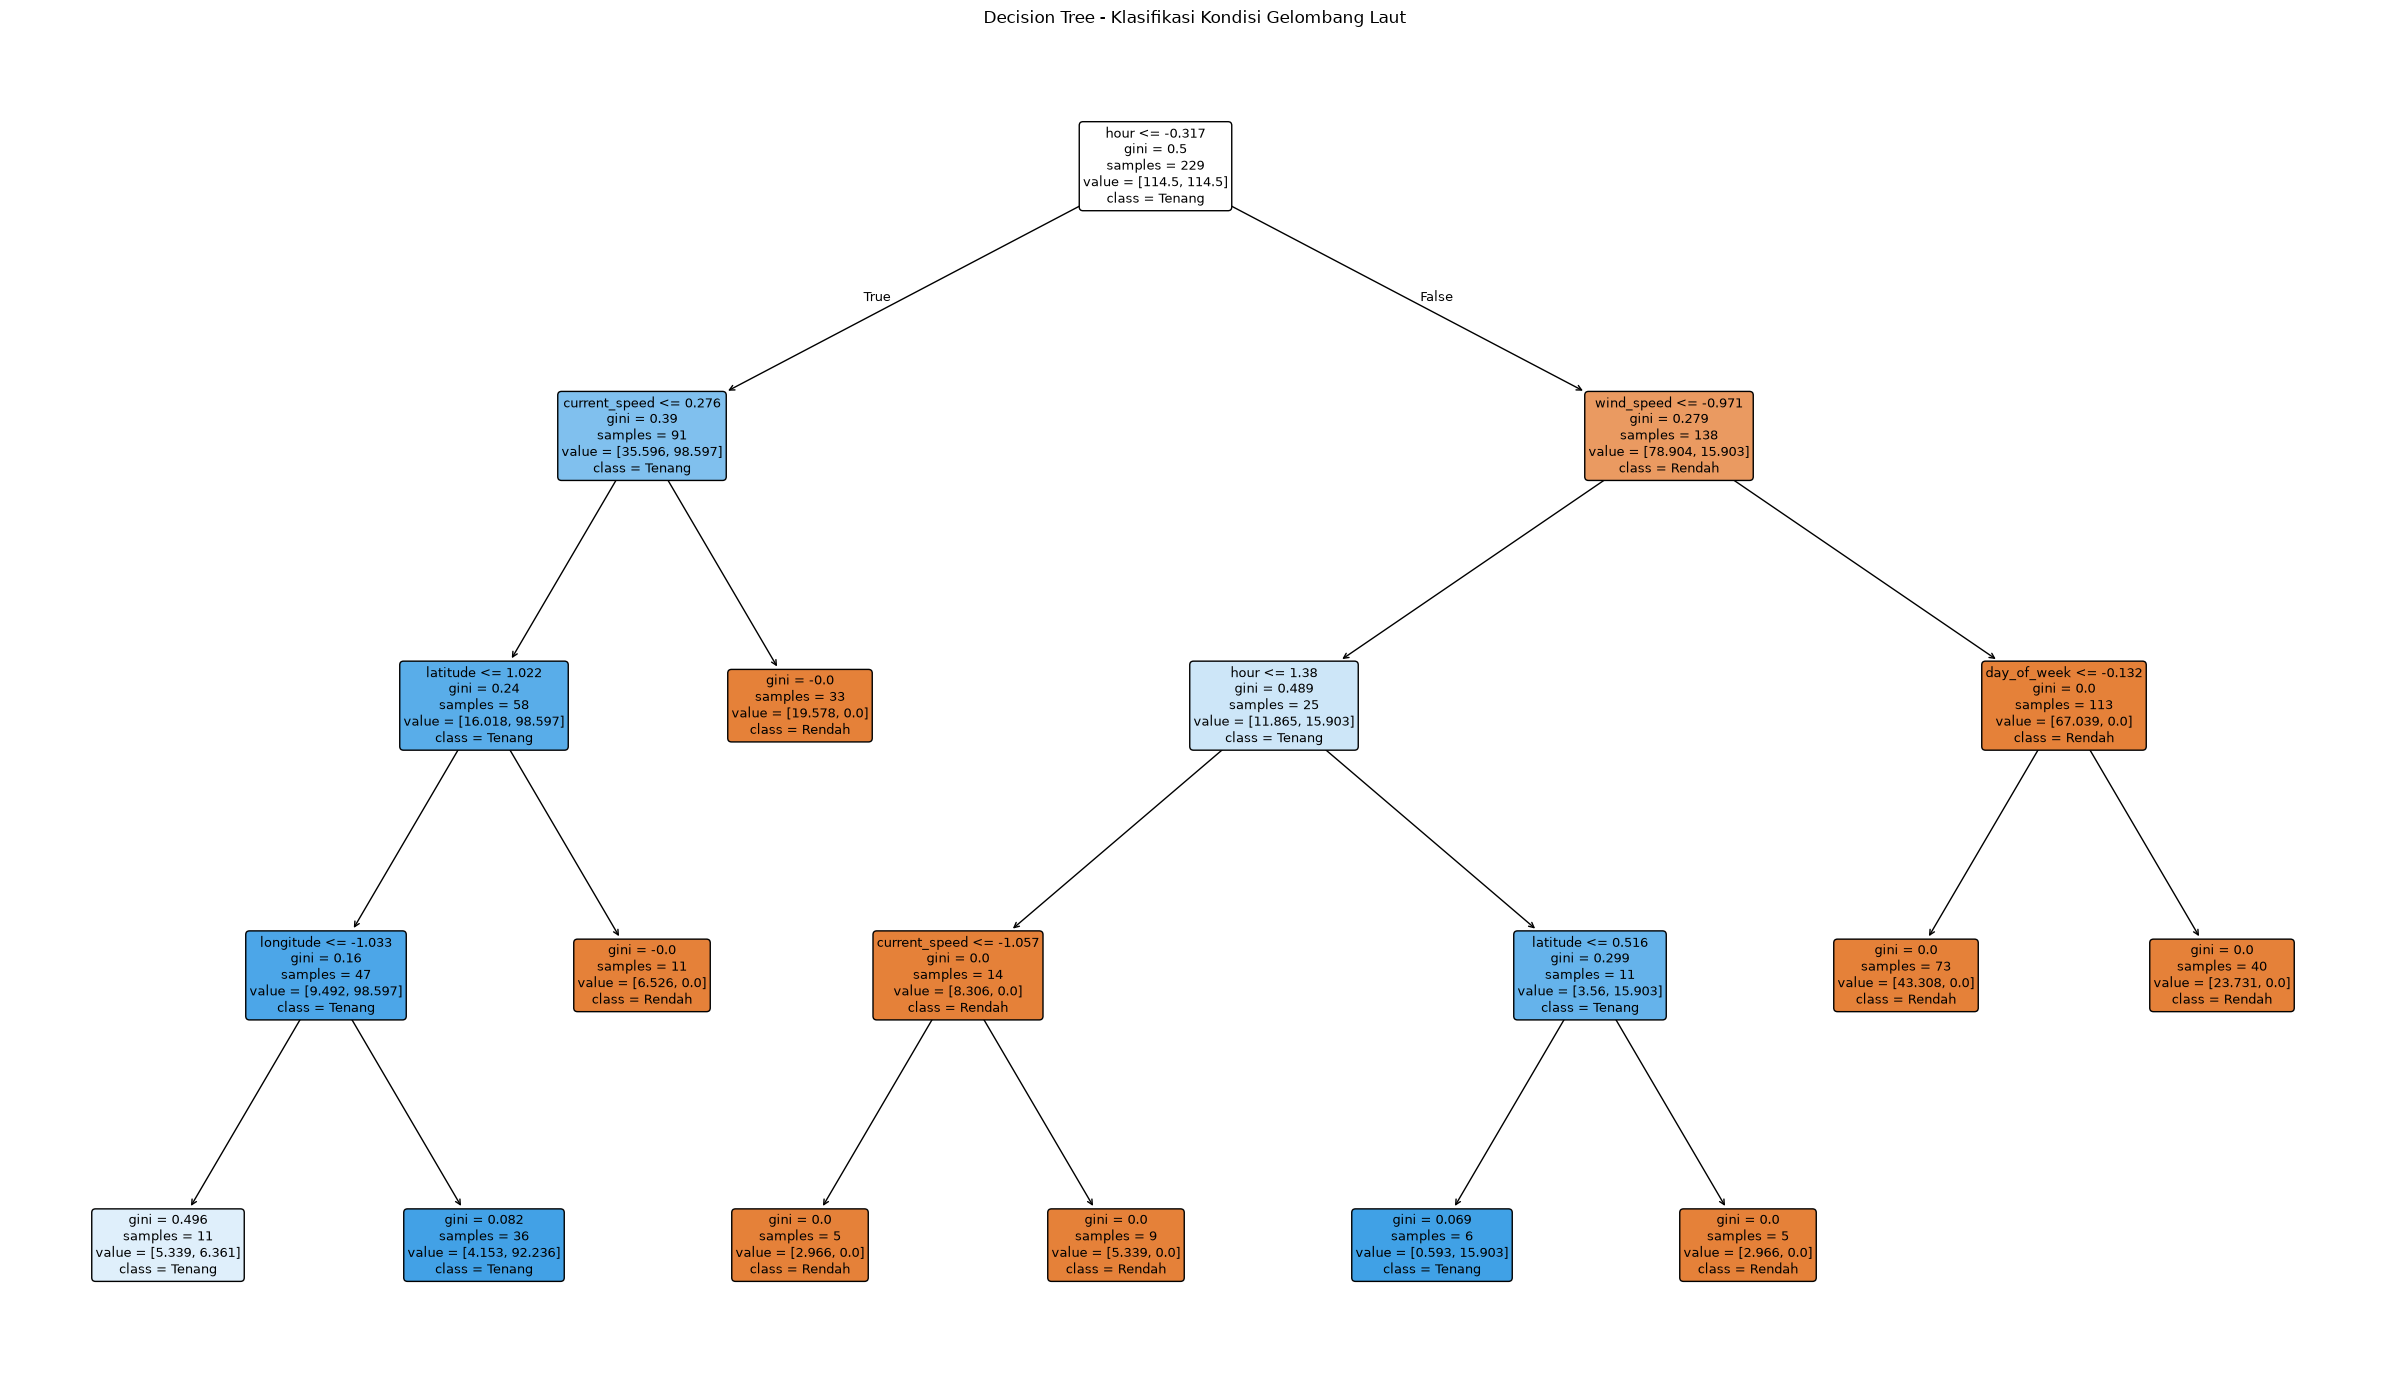

In [ ]:
# ============================================================
# 22. VISUALISASI POHON KEPUTUSAN
# ============================================================

print("\n" + "=" * 80)
print("VISUALISASI DECISION TREE")
print("=" * 80)

plt.figure(
    figsize=(24, 14)
)

plot_tree(

    classifier,

    feature_names=fitur,

    class_names=classifier.classes_,

    filled=True,

    rounded=True,

    fontsize=9
)

plt.title(
    "Decision Tree - Klasifikasi Kondisi Gelombang Laut"
)

plt.tight_layout()

plt.savefig(
    "19_visualisasi_decision_tree.png",
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# 23. INFORMASI STRUKTUR DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INFORMASI DECISION TREE")
print("=" * 80)

print(
    "Max depth:",
    classifier.max_depth
)

print(
    "Actual tree depth:",
    classifier.tree_.max_depth
)

print(
    "Jumlah leaves:",
    classifier.get_n_leaves()
)

# ============================================================
# INSIGHT INFORMASI DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT INFORMASI DECISION TREE")
print("=" * 80)

print("""
Decision Tree yang dibangun memiliki kedalaman maksimum dan
kedalaman aktual sebesar 4, dengan total 6 leaf atau daun
keputusan. Hal ini menunjukkan bahwa model membentuk struktur
keputusan yang terdiri dari beberapa tahapan pemisahan data untuk
membedakan kategori Tenang dan Rendah.

Kedalaman pohon yang dibatasi hingga 4 digunakan untuk menjaga
struktur model agar tidak terlalu kompleks. Dengan jumlah 6 leaf,
model tetap memiliki beberapa aturan keputusan untuk melakukan
klasifikasi tanpa membentuk pohon yang terlalu dalam.
""")


INFORMASI DECISION TREE
Max depth: 4
Actual tree depth: 4
Jumlah leaves: 6

INSIGHT INFORMASI DECISION TREE

Decision Tree yang dibangun memiliki kedalaman maksimum dan
kedalaman aktual sebesar 4, dengan total 6 leaf atau daun
keputusan. Hal ini menunjukkan bahwa model membentuk struktur
keputusan yang terdiri dari beberapa tahapan pemisahan data untuk
membedakan kategori Tenang dan Rendah.

Kedalaman pohon yang dibatasi hingga 4 digunakan untuk menjaga
struktur model agar tidak terlalu kompleks. Dengan jumlah 6 leaf,
model tetap memiliki beberapa aturan keputusan untuk melakukan
klasifikasi tanpa membentuk pohon yang terlalu dalam.



In [ ]:
# ============================================================
# 24. CONTOH HASIL PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("CONTOH HASIL PREDIKSI")
print("=" * 80)

hasil_prediksi = X_test.copy()

hasil_prediksi["aktual"] = y_test.values
hasil_prediksi["prediksi"] = y_pred

print(
    hasil_prediksi.head(10).to_string()
)


# ============================================================
# INSIGHT CONTOH HASIL PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT CONTOH HASIL PREDIKSI")
print("=" * 80)

jumlah_contoh = len(hasil_prediksi.head(10))
jumlah_benar = (
    hasil_prediksi.head(10)["aktual"]
    == hasil_prediksi.head(10)["prediksi"]
).sum()

print(f"""
Contoh hasil prediksi menampilkan {jumlah_contoh} data dari data
testing beserta kategori aktual dan hasil prediksi model. Dari
contoh tersebut, sebanyak {jumlah_benar} data berhasil diprediksi
sesuai dengan kategori aktual. Hasil ini menunjukkan contoh
kemampuan model dalam membedakan kategori Tenang dan Rendah
berdasarkan variabel yang digunakan. Namun, contoh beberapa data
ini hanya digunakan untuk melihat hasil prediksi secara langsung,
sedangkan performa model secara keseluruhan tetap ditentukan
berdasarkan hasil evaluasi pada seluruh data testing.
""")


CONTOH HASIL PREDIKSI
     latitude  longitude  temperature  humidity  wind_speed  wind_gust  current_speed  jumlah_gempa_24jam  magnitude_maks_24jam  jarak_gempa_terdekat_km  aktual prediksi
233     -4.00     122.65         26.0      76.0         2.0       14.0           0.79                   0                   0.0              9999.000000  Tenang   Tenang
127     -3.25     122.60         26.0      81.0         6.0       15.0           0.86                   1                   3.1               143.960281  Rendah   Rendah
250     -3.45     121.75         28.0      73.0         7.0       18.0           0.95                   0                   0.0              9999.000000  Rendah   Rendah
222     -3.45     121.75         27.0      80.0         4.0       12.0           0.94                   0                   0.0              9999.000000  Rendah   Tenang
0       -3.40     122.45         26.0      84.0         2.0        9.0           0.67                   3                   4.5

In [ ]:
# ============================================================
# 25. SIMPAN HASIL PREDIKSI
# ============================================================

hasil_prediksi.to_csv(
    "hasil_prediksi_klasifikasi.csv",
    index=False
)

print(
    "\nFile hasil_prediksi_klasifikasi.csv berhasil dibuat."
)



File hasil_prediksi_klasifikasi.csv berhasil dibuat.


In [ ]:
# ============================================================
# 26. RINGKASAN HASIL
# ============================================================

print("\n" + "=" * 80)
print("RINGKASAN HASIL PROYEK")
print("=" * 80)

print(
    f"\nJumlah data akhir       : {len(df)}"
)

print(
    f"Jumlah fitur ML         : {len(fitur)}"
)

print(
    f"Jumlah data training    : {len(X_train)}"
)

print(
    f"Jumlah data testing     : {len(X_test)}"
)

print(
    f"Accuracy Decision Tree  : {accuracy * 100:.2f}%"
)

print(
    f"CV Mean Accuracy        : {cv_scores.mean() * 100:.2f}%"
)

print(
    f"CV Std                  : {cv_scores.std():.4f}"
)

print("\nFeature paling berpengaruh:")

print(
    feature_importance.head(5).to_string(
        index=False
    )
)




RINGKASAN HASIL PROYEK

Jumlah data akhir       : 287
Jumlah fitur ML         : 12
Jumlah data training    : 229
Jumlah data testing     : 58
Accuracy Decision Tree  : 91.38%
CV Mean Accuracy        : 90.97%
CV Std                  : 0.0706

Feature paling berpengaruh:
      feature  importance
         hour    0.436689
current_speed    0.248472
     latitude    0.149745
   wind_speed    0.129314
    longitude    0.035780


In [ ]:
# ============================================================
# SELESAI
# ============================================================

print("\n" + "=" * 80)
print("SELURUH PROSES SELESAI")
print("=" * 80)

print("""
VISUALISASI YANG DIHASILKAN:

BQ1 - Kondisi Gelombang per Wilayah
1.  bq1_01_jumlah_kategori_per_wilayah.png
2.  bq1_02_proporsi_kategori_per_wilayah.png
3.  bq1_03_boxplot_tinggi_gelombang_wilayah.png
4.  bq1_04_boxplot_angin_wilayah.png

BQ2 - Hubungan Faktor Cuaca dan Kondisi Laut
5.  bq2_05_scatter_angin_vs_gelombang.png
6.  bq2_06_scatter_arus_vs_gelombang.png
7.  bq2_07_scatter_angin_vs_arus.png
8.  bq2_08_correlation_heatmap.png
9.  bq2_09_boxplot_angin_kategori.png
10. bq2_10_boxplot_arus_kategori.png
11. bq2_11_boxplot_temperature_kategori.png
12. bq2_12_boxplot_humidity_kategori.png

BQ3 - Lokasi dan Waktu
13. bq3_13_spatial_gelombang.png
14. bq3_14_temporal_tinggi_gelombang.png
15. bq3_15_temporal_kategori_gelombang.png
16. bq3_16_heatmap_wilayah_waktu.png

Machine Learning
17. 17_confusion_matrix_decision_tree.png
18. 18_feature_importance_decision_tree.png
19. 19_visualisasi_decision_tree.png

Output
20. hasil_prediksi_klasifikasi.csv
""")

print("=" * 80)


SELURUH PROSES SELESAI

VISUALISASI YANG DIHASILKAN:

BQ1 - Kondisi Gelombang per Wilayah
1.  bq1_01_jumlah_kategori_per_wilayah.png
2.  bq1_02_proporsi_kategori_per_wilayah.png
3.  bq1_03_boxplot_tinggi_gelombang_wilayah.png
4.  bq1_04_boxplot_angin_wilayah.png

BQ2 - Hubungan Faktor Cuaca dan Kondisi Laut
5.  bq2_05_scatter_angin_vs_gelombang.png
6.  bq2_06_scatter_arus_vs_gelombang.png
7.  bq2_07_scatter_angin_vs_arus.png
8.  bq2_08_correlation_heatmap.png
9.  bq2_09_boxplot_angin_kategori.png
10. bq2_10_boxplot_arus_kategori.png
11. bq2_11_boxplot_temperature_kategori.png
12. bq2_12_boxplot_humidity_kategori.png

BQ3 - Lokasi dan Waktu
13. bq3_13_spatial_gelombang.png
14. bq3_14_temporal_tinggi_gelombang.png
15. bq3_15_temporal_kategori_gelombang.png
16. bq3_16_heatmap_wilayah_waktu.png

Machine Learning
17. 17_confusion_matrix_decision_tree.png
18. 18_feature_importance_decision_tree.png
19. 19_visualisasi_decision_tree.png

Output
20. hasil_prediksi_klasifikasi.csv

